# Assignment Mini Project

# Import Data & library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("ebay_womens_perfume.csv")
display(df)

,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
0,Carolina Herrera,Good Girl by Carolina Herrera 2.7 oz Eau De Pa...,Eau de Parfum,43.99,US $43.99/ea,2.0,2 available / 393 sold,393.0,"May 23, 2024 10:43:50 PDT","Thomasville, Alabama, United States"
1,As Shown,Parfums de Marly Delina La Rosee Eau de Parfum...,Eau de Parfum,79.99,US $79.99,5.0,5 available / 40 sold,40.0,"May 24, 2024 00:15:48 PDT","New Jersey, Hong Kong"
2,PRADA,PRADA Paradoxe by Prada EDP 3.0oz/90ml Spray P...,Eau de Parfum,59.99,US $59.99,10.0,More than 10 available / 35 sold,35.0,"May 14, 2024 20:54:25 PDT","Orange, New Jersey, United States"
3,As Show,J'adore Parfum D'eau by Christian 3.4 oz EDP F...,Eau de Parfum,59.99,US $59.99/ea,10.0,More than 10 available / 9 sold,9.0,"May 23, 2024 01:23:05 PDT","USA, New Jersey, Hong Kong"
4,Khadlaj,Shiyaaka for Men EDP Spray 100ML (3.4 FL.OZ) B...,Eau de Parfum,29.99,US $29.99/ea,10.0,More than 10 available,NaN,NaN,"Little Ferry, New Jersey, United States"
...,...,...,...,...,...,...,...,...,...,...
995,Avon,Avon Far Away Infinity Eau de Parfum 1.7 fl. o...,Eau de Parfum,13.89,US $13.89,10.0,More than 10 available / 157 sold,157.0,"May 16, 2024 22:35:29 PDT","West Palm Beach, Florida, United States"
996,Mancera,Roses Greedy by Mancera perfume for unisex EDP...,Eau de Parfum,57.85,US $57.85/ea,33.0,33 available / 58 sold,58.0,"May 24, 2024 08:03:11 PDT","Dallas, Texas, United States"
997,Unbranded,"Sweet Tooth Eau de Parfum, Perfume for Women, ...",1,30.96,US $30.96,2.0,2 available / 3 sold,3.0,"May 17, 2024 23:16:41 PDT","New York, New York, United States"
998,Juliette Has A Gun,MMMM BY Juliette Has A Gun perfume for her EDP...,Eau de Perfume,53.99,US $53.99/ea,3.0,3 available / 117 sold,117.0,"May 13, 2024 22:19:34 PDT","Dallas, Texas, United States"


In [3]:
print("(Baris , Kolom) = ",df.shape)
df.columns

(Baris , Kolom) =  (1000, 10)


Index(['brand', 'title', 'type', 'price', 'priceWithCurrency', 'available',
       'availableText', 'sold', 'lastUpdated', 'itemLocation'],
      dtype='str')

Data Ebay Womans Parfume ini memiliki 1000 Baris dan 10 Kolom. Masing-masing kolom berisi beragam informasi mulai dari Brand, Title, Price, Availability, dan banyak data pendukung pada kolom lainnya.

# Data Checking

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              999 non-null    str    
 1   title              1000 non-null   str    
 2   type               998 non-null    str    
 3   price              1000 non-null   float64
 4   priceWithCurrency  1000 non-null   str    
 5   available          869 non-null    float64
 6   availableText      992 non-null    str    
 7   sold               984 non-null    float64
 8   lastUpdated        927 non-null    str    
 9   itemLocation       1000 non-null   str    
dtypes: float64(3), str(7)
memory usage: 260.2 KB


Penjelasan :

- Dataset memiliki total 1000 Data dan 10 kolom

- Dataset memiliki beberapa kolom yang memiliki missing value dilihat dari non - null count dibawah 1000, yaitu Brand, type, available, availableText,sold, dan lastUpdated

- Diduga ada kesalahan dtype pada kolom lastUpdated, yang merupakan tanggal, namun berbentuk string.

- Price dalam Rupiah memang tidak dapat berbentuk float, namun pada case ini berbentuk dollar, jadi memungkinkan berbentuk float.

- Kolom Available dan Sold berisi informasi jumlah persediaan barang, dalam case ini berbentuk parfume yang tidak mungkin dijual kurang dari 1, sehingga seharusnya berbentuk integer.

## Check Missing Value

In [5]:
df.isnull().sum()

brand                  1
title                  0
type                   2
price                  0
priceWithCurrency      0
available            131
availableText          8
sold                  16
lastUpdated           73
itemLocation           0
dtype: int64

In [6]:
df.isnull().sum() / len(df) * 100

brand                 0.1
title                 0.0
type                  0.2
price                 0.0
priceWithCurrency     0.0
available            13.1
availableText         0.8
sold                  1.6
lastUpdated           7.3
itemLocation          0.0
dtype: float64

Penjelasan :
dari pengecheckan missing value, dilihat terdapat beberapa kolom yang memiliki missing value atau data yang kosong. Kolom "Available" memiliki missing value terbanyak dengan total 131 data. Selain itu ada Brand, Type, AvailableText, Sold,dan LastUpdate yang juga memiliki Missing Value.

Data ini akan di check lebih lanjut, agar dapat diketahui apakah perlu di hapus atau diisi dengan data buatan.

## Check Data Numerik

In [7]:
df.describe()

,price,available,sold
count,1000.000000,869.000000,984.000000
mean,39.892980,21.426928,497.321138
std,29.072186,51.476703,1372.510561
min,1.990000,2.000000,1.000000
25%,20.700000,6.000000,15.000000
50%,32.990000,10.000000,52.000000
75%,49.990000,10.000000,263.750000
max,299.990000,557.000000,17854.000000


Penjelasan: 
Dari pengecekan data numerik yang sudah dilakukan, terdapat 3 kolom yang berisi data numerik, yaitu Price, Available, dan Sold.

Pada kolom Price, Count menunjukan semua data tersedia tanpa ada missing. Mean menunjukan 39.8 yang tidak jauh dari median atau 50% data di 32.9.

Pada kolom available, Count menunjukan adanya missing karena kurang dari 1000, mean di 21.4 sedikit lebih tinggi dari median di angka 10, dengan data tertinggi di 557. di asumsikan ada beberapa SKU yang memiliki stock available cukup banyak dibandingkan dengan SKU lain, karena mean dan maxnya cukup jauh.

Pada kolom Sold, count menunjukan ada missing value walaupun tidak sebanyak available. dengan mean 497 yang terbilang cukup jauh dengan median di angka 52. Terlebih data tertinggi atau "max" ada di angka 17854 yang sangat jauh dari median dan meannya. dari kolom ini, pengecekan outlier data wajib dilakukan karena distribusi data pada kolom ini sedikit ekstrem.

## Check Data Categorical

In [8]:
df.describe(include="str")

,brand,title,type,priceWithCurrency,availableText,lastUpdated,itemLocation
count,999,1000,998,1000,992,927,1000
unique,247,975,71,655,746,911,299
top,Lancôme,Idole by Lancome Eau de Parfum EDP Perfume for...,Eau de Parfum,US $49.99/ea,More than 10 available / 3 sold,"May 08, 2024 16:32:50 PDT","Dallas, Texas, United States"
freq,37,4,562,20,7,5,141


In [9]:
df["brand"].value_counts()

brand
Lancôme                      37
Versace                      33
Dolce&Gabbana                30
Jo Malone                    29
Carolina Herrera             27
                             ..
DKNY                          1
United Colors of Benetton     1
Maison                        1
Vince Camuto                  1
Juliette Has A Gun            1
Name: count, Length: 247, dtype: int64

In [10]:
df["type"].value_counts()

type
Eau de Parfum            562
Eau de Toilette          185
Perfume                   56
Eau de Cologne            37
Eau de Perfume            23
                        ... 
Pink Sugar                 1
Oil Perfume                1
FRAGRANCE BODY MIST        1
Eau de Parfum/Perfume      1
1                          1
Name: count, Length: 71, dtype: int64

In [11]:
df["itemLocation"].value_counts()

itemLocation
Dallas, Texas, United States              141
Hackensack, New Jersey, United States      85
Brooklyn, New York, United States          35
Miami, Florida, United States              32
Edison, New Jersey, United States          26
                                         ... 
Battle Creek, Michigan, United States       1
Chino, California, United States            1
Mount Holly, New Jersey, United States      1
Lodi, California, United States             1
Poway, California, United States            1
Name: count, Length: 299, dtype: int64

Penjelasan :

Setelah dilakukan pengecekan data categorical, dapat dilihat bahwa brand dengan data yang paling sering muncul ada pada "Lancome", pada kolom Title ada "Idole by Lancome", type parfume paling banyak muncul ada "Eu de parfume", dan lokasi paling banyak muncul di "Dallas,Texas,United States".

## Check Data Duplicate

In [12]:
df.duplicated().sum()

np.int64(1)

In [13]:
df[df.duplicated(keep=False)]

,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
344,FLOWER,12 Piece Woman’s Perfume Lot: Assorted scents ...,Perfume,48.0,US $48.00,4.0,4 available / 1 sold,1.0,NaN,"Webster, Florida, United States"
662,FLOWER,12 Piece Woman’s Perfume Lot: Assorted scents ...,Perfume,48.0,US $48.00,4.0,4 available / 1 sold,1.0,NaN,"Webster, Florida, United States"


Penjelasan :

Setelah dilakukan pengecheckan duplicate dapat dilihat bahwa terdapat 1 data yang sama persis di semua kolom. Karena bentuk datanya adalah data tracker stock Parfume, diasumsikan bahwa data duplicate ini benar duplicate dan bisa di hapus.

# Data Exploration

## Numeric Data Exploration

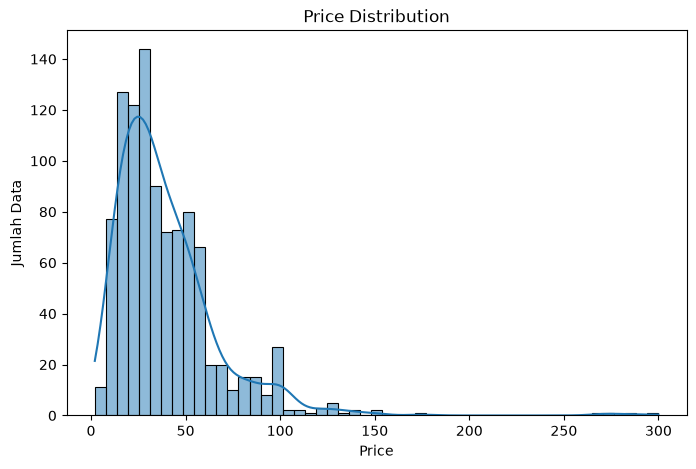

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="price", kde=True)

plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Jumlah Data")
plt.show()
    

Penjelasan :
Setelah dibuat menjadi grafik histogram, dapat dilihat bentuk grafik price distribution berbentuk Right/Positive Skewed. Dari grafik ini terindikasi ada beberapa produk yang secara harga lebih mahal dari mayoritas parfum yang lain.

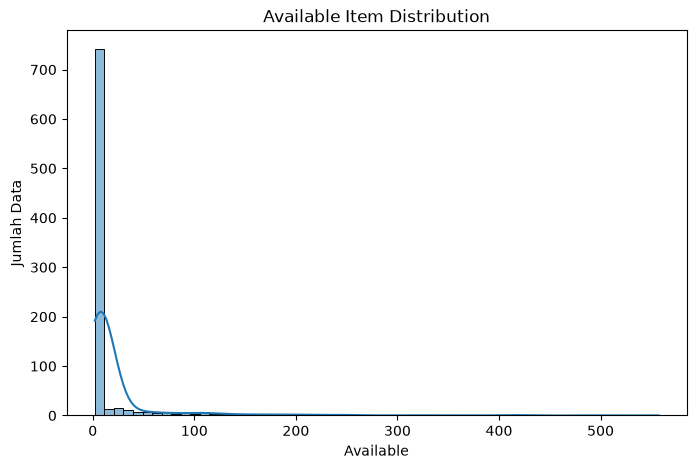

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="available", kde=True)

plt.title("Available Item Distribution")
plt.xlabel("Available")
plt.ylabel("Jumlah Data")
plt.show()

Penjelasan :
Setelah dibuat menjadi grafik histogram, dapat dilihat bentuk grafik Available Item Distribution berbentuk Right/Positive Skewed. Dari grafik ini terindikasi ada beberapa produk yang secara stock atau availability lebih banyak dari mayoritas parfum yang lain. Sebagai pengingat, data yang digunakan masih terdapat missing value, jadi ini baru indikasi awal.

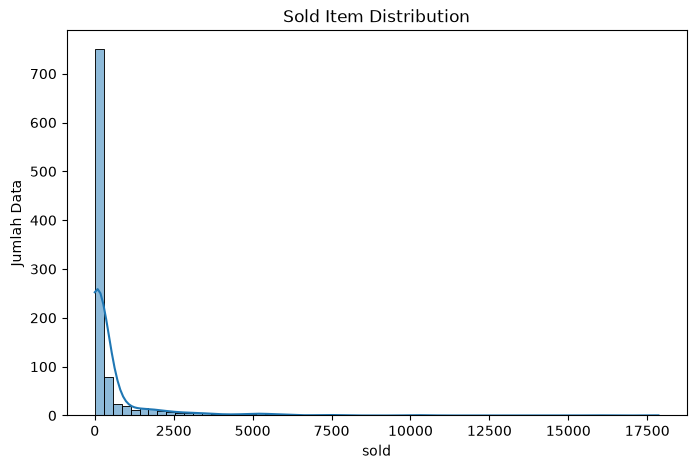

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="sold", kde=True)

plt.title("Sold Item Distribution")
plt.xlabel("sold")
plt.ylabel("Jumlah Data")
plt.show()

Penjelasan :
Setelah dibuat menjadi grafik histogram, dapat dilihat bentuk grafik Sold Item Distribution berbentuk Right/Positive Skewed. Dari grafik ini terindikasi ada beberapa produk yang secara penjualan terbilang jauh lebih tinggi dari mayoritas parfum yang lain, bahkan ada parfum yang terjual sekitar 17.500 unit.

## Categorical Data Exploration

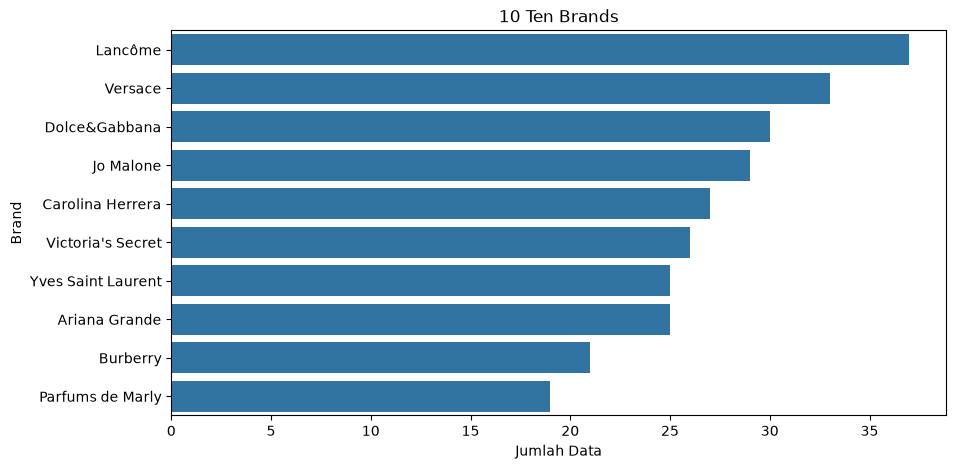

In [17]:
top10_brand = df["brand"].value_counts().head(10)
plt.figure(figsize=(10,5))

sns.barplot(x=top10_brand.values, y=top10_brand.index)

plt.title("10 Ten Brands")
plt.xlabel("Jumlah Data")
plt.ylabel("Brand")
plt.show()

Penjelasan : Dari Bar Chart yang sudah dibuat, dapat dilihat bahwa Lancome adalah parfume yang paling banyak muncul, selanjutnya ada Versace, dan Dolce&Gabbana. Sebagai pengingat data yang digunakan masih data mentah yang belum di cleaning, sehingga masih dapat terjadi perubahan data jika ada data lain yang merupakan brand yang sama, namun dihitung terpisah karena typo.

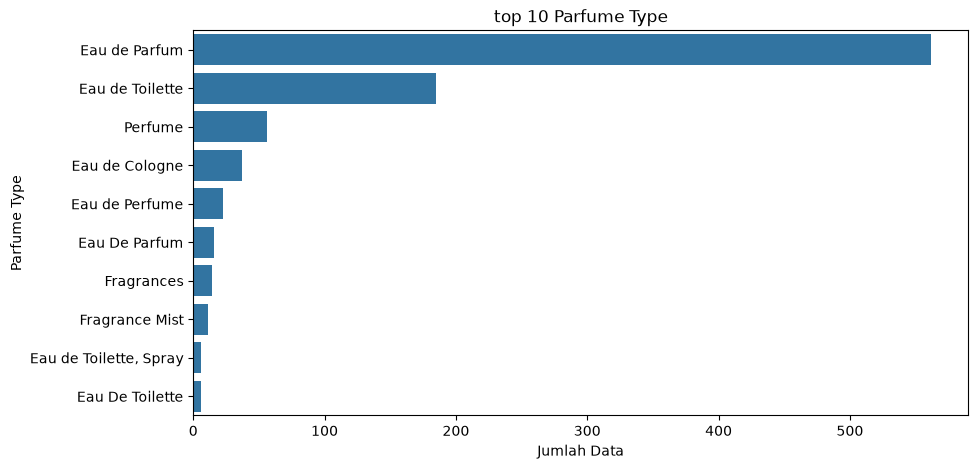

In [18]:
tipeparfum = df["type"].value_counts().head(10)
plt.figure(figsize=(10,5))

sns.barplot(x=tipeparfum.values, y=tipeparfum.index)

plt.title("top 10 Parfume Type")
plt.xlabel("Jumlah Data")
plt.ylabel("Parfume Type")
plt.show()

Penjelasan : Dari Bar Chart yang sudah dibuat, dapat dilihat type yang paling banyak muncul adalah "Eau de Parfum". Selain itu dapat dilihat bahwa ada data lain yang secara penulisan berbeda tapi memiliki kemiripan yang merujuk pada 1 type yang sama.

Contohnya :
- Eau de Parfum dan Eau de Parfume
- Eau de Toilette dan Eau de Toillette

Grafik ini memberikan bukti bahwa terdapat inkonsistensi penulisan dan perlu dilakukannya data cleaning.

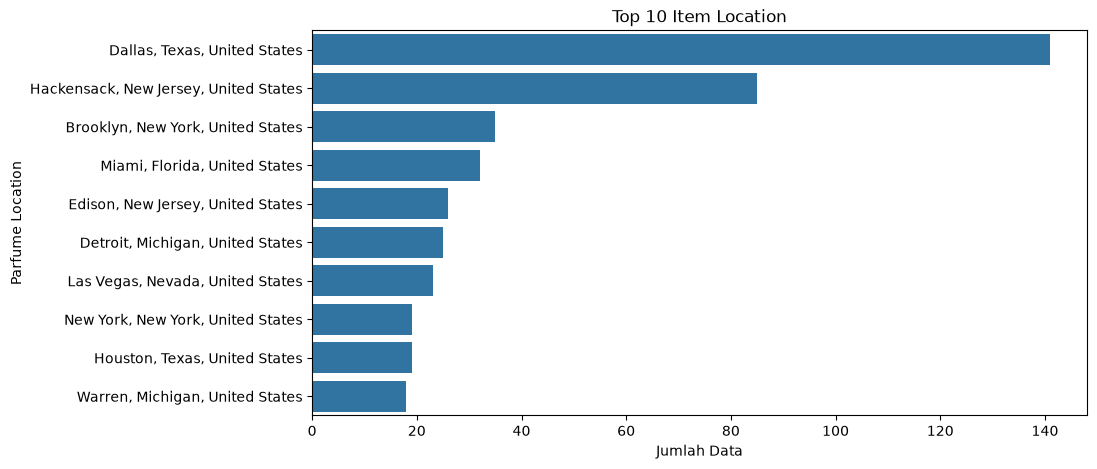

In [19]:
lokasiparfum = df["itemLocation"].value_counts().head(10)
plt.figure(figsize=(10,5))

sns.barplot(x=lokasiparfum.values, y=lokasiparfum.index)

plt.title("Top 10 Item Location")
plt.xlabel("Jumlah Data")
plt.ylabel("Parfume Location")
plt.show()

Penjelasan : Dari Bar Chart yang sudah dibuat, dapat dilihat bahwa "Dallas, Texas, United States" adalah lokasi item yang paling banyak muncul.

## Data Exploration Summary

Berdasarkan hasil Eksplorasi Data, terdapat beberapa hal yang perlu difokuskan :

- Distribusi data numerik yaitu kolom Price, Available, dan Sold memiliki bentuk histogram Right/Positive Skewed, serta memiliki beberapa nilai extreem khususnya pada kolom Price. Hal ini menunjukan diperlukan pengecheckan lebih lanjut apakah nilai extreem tersebut merupakan Outlier atau bukan.
- Pada data kategorikal juga ditemukan inkonsistensi penulisan seperti perbedaan huruf kapital, kelebihan huruf, dan variasi penulisan lainnya, padahal secara makna data tersebut memiliki arti yang sama. maka dari itu perlu dilakukan data cleaning untuk menghasilkan output kategori yang lebih konsisten agar proses analisa selanjutnya lebih akurat.

# Data Cleaning

Berdasarkan Data Exploration yang sudah dilakukan sebelumnya, akan dilakukan penanganan data yang meliputi :
- Penanganan Missing Value
- Duplicate Data
- Inkonsistensi Penulisan Data
- Checking Outlier berdasarkan nilai extreem yang terindikasi

## Missing Value

In [20]:
missing_value = pd.DataFrame({
    "Jumlah Missing Data": df.isnull().sum(),
    "Persentase (%) Jumlah Missing Data": (df.isnull().sum() / len(df)) * 100
})

display(missing_value)

,Jumlah Missing Data,Persentase (%) Jumlah Missing Data
brand,1,0.1
title,0,0.0
type,2,0.2
price,0,0.0
priceWithCurrency,0,0.0
available,131,13.1
availableText,8,0.8
sold,16,1.6
lastUpdated,73,7.3
itemLocation,0,0.0


### Penanganan kolom "brand"

In [21]:
display(df[df["brand"].isnull()])

,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
856,NaN,Bright Crystal de Versace Eau de Toilette 3.0 ...,NaN,29.99,US $29.99,NaN,2 disponibles / 3 vendidos,NaN,23 may 2024 02:42:14 EST,"Hamtramck, Michigan, Estados Unidos"


Penjelasan : Dari data berikut, kolom Brand kosong atau NaN tapi kolom title terisi, sehingga kita bisa mengisi isinya sesuai dengan brand yang terdapat di kolom title.

In [22]:
'''pengisian kolom brand'''

df.loc[856,"brand"] = "Versace" #.loc untuk menentukan index dan kolom pengisian data

In [23]:
display(df.loc[[856]]) #display kolom yang sudah terisi

,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
856,Versace,Bright Crystal de Versace Eau de Toilette 3.0 ...,NaN,29.99,US $29.99,NaN,2 disponibles / 3 vendidos,NaN,23 may 2024 02:42:14 EST,"Hamtramck, Michigan, Estados Unidos"


Notes : Kolom Brand sudah berhasil diisi

### Penanganan Kolom "type"

In [24]:
display(df[df["type"].isnull()])

,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
463,As Show,Carmina By Creed EDP 75ml 2.5 oz Spray For Wom...,NaN,128.88,US $128.88,10.0,10 available / 21 sold,21.0,"May 24, 2024 00:32:16 PDT","New Jersey, United States, Hong Kong"
856,Versace,Bright Crystal de Versace Eau de Toilette 3.0 ...,NaN,29.99,US $29.99,NaN,2 disponibles / 3 vendidos,NaN,23 may 2024 02:42:14 EST,"Hamtramck, Michigan, Estados Unidos"


In [25]:
#penanganan sama seperti pada kolom "brand"
df.loc[463,"type"] = "Eau de Parfum"
df.loc[856,"type"] = "Eau de Toilette"

In [26]:
#display kolom yang sudah terisi
display(df.loc[[463]])
display(df.loc[[856]])

,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
463,As Show,Carmina By Creed EDP 75ml 2.5 oz Spray For Wom...,Eau de Parfum,128.88,US $128.88,10.0,10 available / 21 sold,21.0,"May 24, 2024 00:32:16 PDT","New Jersey, United States, Hong Kong"


,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
856,Versace,Bright Crystal de Versace Eau de Toilette 3.0 ...,Eau de Toilette,29.99,US $29.99,NaN,2 disponibles / 3 vendidos,NaN,23 may 2024 02:42:14 EST,"Hamtramck, Michigan, Estados Unidos"


Notes : Kolom "type" sudah berhasil diisi

### Penanganan kolom "Avaialable"

In [27]:
display(df.loc[df["available"].isnull(),["title","available","availableText"]])

,title,available,availableText
6,PRADA Paradoxe by Prada EDP 3.0oz/90ml Spray P...,NaN,Out of Stock / 18 sold
8,Versace Bright Crystal by Versace for Women ED...,NaN,Last One / 251 sold
18,PRADA Paradoxe By Prada EDP 3.0oz/90ml Spray P...,NaN,Last One / 43 sold
23,Libre by Yves Saint Laurent YSL 3 oz EDP Perfu...,NaN,Last One / 25 sold
27,Dolce & Gabbana Light Blue 6.7 oz Spray Eau De...,NaN,Out of Stock / 54 sold
...,...,...,...
975,Gucci Guilty 1.7 oz EDT Perfume for Women New ...,NaN,Limited quantity available / 275 sold
982,Carmina By Creed2.5 oz / 75 ml Eau De Parfum F...,NaN,Last One / 3 sold
983,Burberry Her ELIXIR DE PARFUM EDP Intense-Delu...,NaN,NaN
990,United Colors of Benetton MINI COLORS FEMME WO...,NaN,4 lots available (8 items per lot) / 79 sold


Untuk mengisi kolom available, ada informasi yang bisa kita ambil dari kolom lain yaitu "availableText"

In [28]:
#mendeteksi variasi isi dari availableText

'''
display untuk memunculkan, df.loc untuk menentukan baris dan kolom yang ingin dipanggil.
baris yang ingin dipanggil adalah kolom available yang kosong, df["available"].isnull()
sedangkan kolom yang ingin dipanggil adalah kolom "availableText"

Setelah ditentukan kolom yang dipanggil, kita ingin memunculkan jumlah kolomnya menggunakan .value_counts
Supaya NaN atau kolom availableText yang kosong tetap terhitung kita menambahkan dropna=False
'''

display(df.loc[df["available"].isnull(),"availableText"].value_counts(dropna=False))

availableText
NaN                                             8
Last One / 5 sold                               4
Last One / 11 sold                              4
Last One / 6 sold                               3
Last One / 1 sold                               3
                                               ..
Last One / 678 sold                             1
Limited quantity available / 272 sold           1
Limited quantity available / 275 sold           1
Last One / 3 sold                               1
4 lots available (8 items per lot) / 79 sold    1
Name: count, Length: 101, dtype: int64

Setelah di check, kolom "availableText" memiliki beberapa variasi input, seperti "Last one", "Limited Quantity", dan "lots available"

In [29]:
#menghitung masing-masing variasi data pada "availableText"
missing_available = df.loc[df["available"].isnull(),"availableText"]

print("Last One:", missing_available.str.contains("Last One", case=False, na=False).sum())
print("Limited quantity:", missing_available.str.contains("Limited quantity", case=False, na=False).sum())
print("available:", missing_available.str.contains("available", case=False, na=False).sum())
print("NaN", missing_available.isnull().sum())

Last One: 73
Limited quantity: 44
available: 47
NaN 8


Dari beberapa bentuk data yang ada, yang memiliki arti lebih pasti adalah "Last One", bisa diintepretasikan sebagai "sisa 1" atau "stock terakhir" maka, kita bisa mengisi kolom "available" dengan angka 1

In [30]:
last_one = (df["available"].isnull() & df["availableText"].str.contains("Last One", case=False, na=False))

df.loc[last_one, "available"] = 1

Setelah kolom available yang "availableText"nya berisi "Last One" sudah diisi dengan angka 1, ada 73 missing value yang sudah terisi.

In [31]:
print("Missing available sebelum: 131")
print("Missing available sesudah:", df["available"].isnull().sum())

Missing available sebelum: 131
Missing available sesudah: 58


In [32]:
#pengecheckan data "availableText" yang NaN
display(df.loc[df["availableText"].isna()])

,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation
121,Ellis Brooklyn,NWB Ellis Brooklyn Miami Nectar Eau de Parfum ...,Eau de Parfum,33.00,US $33.00,NaN,NaN,NaN,NaN,"Cranford, New Jersey, United States"
602,Giardini Di Toscana,Bianco Latte EDP by Giardini Di Toscana 100 M...,Perfume,140.00,US $140.00,NaN,NaN,NaN,NaN,"Houston, Texas, United States"
732,CHANEL,CHANEL Les Eaux De Chanel Paris Eau De Toilett...,Eau de Toilette,24.00,US $24.00,NaN,NaN,NaN,NaN,"Los Angeles, California, United States"
827,Ellis Brooklyn,NWB Ellis Brooklyn Biography Fragrance Discove...,Discovery Set,17.00,US $17.00,NaN,NaN,NaN,NaN,"Edison, New Jersey, United States"
839,Lomani,SPICE ADDICT PRIVATE COLLECTION BY LOMANI EDP ...,Eau de Parfum,84.00,US $84.00,NaN,NaN,NaN,NaN,"Hialeah, Florida, United States"
880,Burberry,Burberry Goddess EDP Eau De Parfum Spray 3.3 o...,Eau de Parfum,95.00,US $95.00,NaN,NaN,NaN,NaN,"West Hollywood, California, United States"
927,Snif,"Snif : Sweet Ash .07 FL. OZ. - Juniper, Fir Ba...",Perfume,14.95,US $14.95,NaN,NaN,NaN,NaN,"Philadelphia, Pennsylvania, United States"
983,Burberry,Burberry Her ELIXIR DE PARFUM EDP Intense-Delu...,Eau de Parfum,13.00,US $13.00,NaN,NaN,NaN,NaN,"Chino, California, United States"


Dari tabel diatas, kolom available, avaialbleText, sold, dan lastUpdated kosong, sedangkan dalam kolom lain tidak ada informasi yang bisa dijadikan acuan untuk mengisi kolom yang kosong. maka dari itu, sementara saya membiarkan data tersebut kosong. saya tidak menghapus karena data di kolom lain masih bisa digunakan untuk bahan analisa yang tidak memerlukan data available dan sold, setelah data missing value lain terisi, baru akan ditentukan apakah akan diisi dengan mean atau median, sesuai kebutuhan analisa.

In [33]:
#pengecekan ulang setelah pengisian angka 1 pada Lastone sebelumnya
display(df.loc[df["available"].isna(),"availableText"].value_counts(dropna=False))

availableText
NaN                                                         8
Limited quantity available / 119 sold                       2
Out of Stock / 18 sold                                      1
Out of Stock / 54 sold                                      1
Limited quantity available / 1,571 sold                     1
Limited quantity available / 1,484 sold                     1
Limited quantity available / 5,587 sold                     1
Limited quantity available / 4,332 sold                     1
Limited quantity available / 5,901 sold                     1
Limited quantity available / 252 sold                       1
Limited quantity available / 7,018 sold                     1
Limited quantity available / 1,790 sold                     1
Limited quantity available / 99 sold                        1
Limited quantity available / 6,191 sold                     1
Limited quantity available / 3,080 sold                     1
Limited quantity available / 7,331 sold                 

setelah dilakukan pengecekan ulang, dapat dilihat ada data yang belum terlihat sebelumnya, yaitu "out of stock". data ini bisa diintepretasikan sebagai stock habis atau 0.

In [34]:
#mengisi kolom dengan keterangan out of stock dengan 0
''' Query yang digunakan sama seperti pada penanganan "last one" '''
outofstock = (df["available"].isna() & df["availableText"].str.contains("Out of Stock", case=False, na=False))

df.loc[outofstock,"available"] = 0

selain out of stock, ada data lain yang berbeda dari data lain yaitu "2 disponible / 3 vendidos", setelah dicari digoogle, disponible artinya "available", dan "vendidos" artinya sold. jadi dapat disimpulkan bahwa keterangan pada baris tersebut adalah 2 Available, dan 3 sold.

In [35]:
#penanganan baris disponibles
disponibles = (df["available"].isna() & df["availableText"].str.contains("2 disponibles", case=False, na=False))

df.loc[disponibles, "available"] = 2

In [36]:
print("Missing available sebelum: 131")
print("Missing available sesudah:", df["available"].isnull().sum())

Missing available sebelum: 131
Missing available sesudah: 55


Setelah 2 data out of stock dan 1 data disponibles diisi, sisa missing value menjadi 55

Dari sisa data yang ada, ada beberapa data yang masih bisa diintepretasikan ytu "lots avaialble" :
- More than 10 lots available (3 items per lot) / 154 sold 
- 3 lots available (10 items per lot) / 26 sold  
- 4 lots available (8 items per lot) / 79 sold

yang memiliki nilai lebih pasti adalah :
- 3 lots vailable (10 items per lot) yang artinya 30 item
- 4 lots available (8 items per lot) yang artinya 32 item

In [37]:
check_lots = df.loc[
    df["available"].isna() &
    df["availableText"].str.contains("lots available", case=False, na=False),
    ["available", "availableText"]
]

display(check_lots)

,available,availableText
358,NaN,3 lots available (10 items per lot) / 26 sold
688,NaN,More than 10 lots available (3 items per lot) ...
990,NaN,4 lots available (8 items per lot) / 79 sold


In [38]:
df.loc[358, "available"] = 30
df.loc[990, "available"] = 32
df.loc[688, "available"] = 33

dari keterangan pada availableText, bisa diintepretasikan bahwa klom lots available bisa menentukan berapa jumlah seharusnya pada kolom available. kecuali pada "more than 10 lots available" kita belum bisa mengetahui stock available secara pasti, hanya bisa mengisinya dengan minimum stock dengan keterangan yang ada, yaitu 33.

In [39]:
print("Sisa Missing Available:", df["available"].isna().sum())

Sisa Missing Available: 52


In [40]:
#pengecekan ulang setelah pengisian angka 1 pada Lastone sebelumnya
display(df.loc[df["available"].isna(),"availableText"].value_counts(dropna=False))

availableText
NaN                                         8
Limited quantity available / 119 sold       2
Limited quantity available / 1,571 sold     1
Limited quantity available / 1,484 sold     1
Limited quantity available / 5,587 sold     1
Limited quantity available / 4,332 sold     1
Limited quantity available / 5,901 sold     1
Limited quantity available / 252 sold       1
Limited quantity available / 7,018 sold     1
Limited quantity available / 1,790 sold     1
Limited quantity available / 99 sold        1
Limited quantity available / 6,191 sold     1
Limited quantity available / 3,080 sold     1
Limited quantity available / 7,331 sold     1
Limited quantity available / 3,759 sold     1
Limited quantity available / 3,379 sold     1
Limited quantity available / 3,009 sold     1
Limited quantity available / 770 sold       1
Limited quantity available / 725 sold       1
Limited quantity available / 953 sold       1
Limited quantity available / 5,349 sold     1
Limited quantity ava

In [41]:
'''membuat kolom keterangan inputasi yang harus diisi dengan median atau mean'''
df["InputNotes"] = ""

untuk memberikan disclaimer, saya membuat kolom baru terhadap data yang saya isi inputnya dengan median

In [42]:
limited_quantity = ( df["available"].isna() & df["availableText"].str.contains( "Limited quantity available", case=False, na=False))

median_available = df["available"].median()

df.loc[limited_quantity, "available"] = median_available
df.loc[limited_quantity, "InputNotes"] = "available diisi median"

In [43]:
print("Median Available:", median_available)
print("Jumlah Limited Quantity yang diisi:", limited_quantity.sum())
print("Sisa Missing Available:", df["available"].isna().sum())

Median Available: 10.0
Jumlah Limited Quantity yang diisi: 44
Sisa Missing Available: 8


Untuk Limited Quantity Available, saya memutuskan dengan mengisinya dengan median, karena berdasarkan informasi dari AvailableText, sebenarnya stock masih ada dalam jumlah terbatas. saya menggunakan median karena jika memakai mean, ada potensi hasil mean akan cenderung terlalu besar, karena adanya nilai extreme pada data ini, yang secara bentuk adalah right/positive skewed.

Sedangkan untuk NaN, saya memutuskan untuk tidak mengisinya dengan apapun karena tidak ada data yang dapat digunakan sebagai dasar. Apalagi data berikut berhubungan dengan informasi stock, jika diisi tidak sesuai dengan data yang ada, dikhawatirkan malah dapat memberikan missinformasi yang berdampak negatif pada operasional.

### Penanganan Kolom Sold

In [44]:
display(df.loc[df["sold"].isna(),["sold","availableText","available"]])

,sold,availableText,available
4,NaN,More than 10 available,10.0
114,NaN,More than 10 available,10.0
117,NaN,2 available,2.0
121,NaN,NaN,NaN
432,NaN,More than 10 available,10.0
496,NaN,4 available,4.0
551,NaN,5 available,5.0
602,NaN,NaN,NaN
617,NaN,More than 10 available,10.0
732,NaN,NaN,NaN


In [45]:
df.loc[856, "sold"] = 3
display(df.loc[[856], ["sold", "availableText","available"]])

,sold,availableText,available
856,3.0,2 disponibles / 3 vendidos,2.0


Berdasarkan informasi sebelumnya, 3 venditos adalah 3 sold, maka untuk data ini saya langsung mengisi angka 3 di kolom sold

In [46]:
print("Sisa Missing Sold:", df["sold"].isna().sum())

print("Mean Sold   :", df["sold"].mean())
print("Median Sold :", df["sold"].median())

Sisa Missing Sold: 15
Mean Sold   : 496.81928934010153
Median Sold : 52.0


Sama seperti kolom available, karena bentuknya Right/Positive Skewed, saya memilih mengisi sisa data yang tidak memiliki informasi pasti berapa jumlah soldnya menjadi Median, agar angkanya tidak dipengaruhi oleh data extreme.

In [47]:
#mengisi data available dan sold dengan median jika 3 kolom berisi NaN
missing_data = (df["available"].isna() & df["availableText"].isna() & df["sold"].isna())

median_available = df["available"].median()
median_sold = df["sold"].median()

df.loc[missing_data, "available"] = median_available
df.loc[missing_data, "sold"] = median_sold

df.loc[missing_data, "InputNotes"] = "available & sold diisi median"

Kolom Sold dan Available yang kosong sudah diisi median, dan diberi keterangan pada InputNotes

In [48]:
display(df.loc[df["sold"].isna(),["sold", "availableText","available", "InputNotes"]])

print("Sisa Missing Sold:", df["sold"].isna().sum())

,sold,availableText,available,InputNotes
4,NaN,More than 10 available,10.0,
114,NaN,More than 10 available,10.0,
117,NaN,2 available,2.0,
432,NaN,More than 10 available,10.0,
496,NaN,4 available,4.0,
551,NaN,5 available,5.0,
617,NaN,More than 10 available,10.0,


Sisa Missing Sold: 7


Sekarang tersisa kolom Sold yang kolom availablenya terisi namun soldnya tidak terisi dan tidak memiliki keterangan pada availableText

In [49]:
missing_sold = df["sold"].isna()

median_sold = df["sold"].median()

df.loc[missing_sold, "sold"] = median_sold
df.loc[missing_sold, "InputNotes"] = "sold diisi median"

Dilakukan hal yang sama, yaitu input median, dan memberikan keterangan pada InputNotes

In [50]:
display(df.loc[missing_sold,["sold", "availableText", "InputNotes","available"]])

print("Sisa Missing Sold:", df["sold"].isna().sum())

,sold,availableText,InputNotes,available
4,52.0,More than 10 available,sold diisi median,10.0
114,52.0,More than 10 available,sold diisi median,10.0
117,52.0,2 available,sold diisi median,2.0
432,52.0,More than 10 available,sold diisi median,10.0
496,52.0,4 available,sold diisi median,4.0
551,52.0,5 available,sold diisi median,5.0
617,52.0,More than 10 available,sold diisi median,10.0


Sisa Missing Sold: 0


Seluruh kolom sold sudah terisi dan diberi keterangan

## Penanganan Kolom Last Update

In [51]:
display(df.loc[df["lastUpdated"].isna(),["title", "sold", "available", "lastUpdated"]].head(10))

,title,sold,available,lastUpdated
4,Shiyaaka for Men EDP Spray 100ML (3.4 FL.OZ) B...,52.0,10.0,NaN
21,CREPE ERASE-BODY FIRM ADVANCED BODY REPAIR TRE...,1.0,10.0,NaN
36,PDM PARFUMS DE MARLY DELINA EXCLUSIF 1.5ml .05...,59.0,10.0,NaN
70,Maison Margiela Replica Sailing Day Eau de Toi...,14.0,10.0,NaN
79,Dossier Ambery Vanilla Eau de Parfum. Size: 50...,10.0,10.0,NaN
80,D&G DOLCE & GABBANA DEVOTION EDP 1.5ml .05fl o...,266.0,10.0,NaN
88,GAP DREAM BODY MIST 8FL OZ/236 mL FREE SHIPPIN...,35.0,10.0,NaN
117,OUAI Hair & Body Mist In ST. BARTS 3.3oz / 97m...,52.0,2.0,NaN
119,Valentino Donna Born In Roma Eau De Parfum 2M...,2.0,10.0,NaN
121,NWB Ellis Brooklyn Miami Nectar Eau de Parfum ...,52.0,10.0,NaN


In [52]:
display(df.loc[df["lastUpdated"].notna(),"lastUpdated"].head(10))

0     May 23, 2024 10:43:50 PDT
1     May 24, 2024 00:15:48 PDT
2     May 14, 2024 20:54:25 PDT
3     May 23, 2024 01:23:05 PDT
5     May 23, 2024 10:44:09 PDT
6     May 24, 2024 00:15:13 PDT
7     May 21, 2024 06:41:13 PDT
8     May 23, 2024 22:39:02 PDT
9     May 24, 2024 00:25:04 PDT
10    May 24, 2024 11:01:13 PDT
Name: lastUpdated, dtype: str

Karena bentuk data LastUpdates adalah tanggal yang memberikan informasi kapan data tersebut terakhir di update. Maka saya memutuskan untuk tidak mengisi kolom tersebut karena tidak ada informasi pendukung yang bisa dijadikan acuan. Jika diisi dengan tanggal hari ini pun, akan menjadi kesalahan karena saya tidak mengecek secara real jumlah stock available maupun ada atau tidaknya penjualan pada kolom sold.

### Summary Missing Value

In [53]:
missing_value_after = pd.DataFrame({"Jumlah Missing Data": df.isnull().sum(),"Persentase (%)": df.isnull().mean() * 100})

display(missing_value_after)

,Jumlah Missing Data,Persentase (%)
brand,0,0.0
title,0,0.0
type,0,0.0
price,0,0.0
priceWithCurrency,0,0.0
available,0,0.0
availableText,8,0.8
sold,0,0.0
lastUpdated,73,7.3
itemLocation,0,0.0


Setelah dilakukannya penanganan Missing Value, kolom "brand","type","available", dan "sold" sudah berhasil ditangani dengan mengisi data sesuai informasi dari kolom lain, dan pengisian median terhadap data yang tidak memiliki informasi pendukung.

Penggunaan Median dipilih karena bentuk data Right Skewed sehingga median lebih aman karena lebih tahan terhadap data extreme.

Untuk menjaga informasi yang dihasilkan tetap valid, saya juga sudah membuat kolom baru yaitu "Input Notes" untuk memberi keterangan bahwa beberapa data diisi dengan Median

Selain kolom tersebut, masih ada data dengan missing value pada kolom availableText dan LastUpdate, namun karena tidak terdapat data pendukung yang bisa digunakan, saya tetap memperthankan missing value tersebut, karena jika dipaksakan untuk diisi dapat memberikan informasi yang tidak akurat.

## Duplicate Data

In [54]:
print("Jumlah Data Duplikat:", df.duplicated().sum())

Jumlah Data Duplikat: 1


In [55]:
duplicate_data = df[df.duplicated(keep=False)]

display(duplicate_data)

,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation,InputNotes
344,FLOWER,12 Piece Woman’s Perfume Lot: Assorted scents ...,Perfume,48.0,US $48.00,4.0,4 available / 1 sold,1.0,NaN,"Webster, Florida, United States",
662,FLOWER,12 Piece Woman’s Perfume Lot: Assorted scents ...,Perfume,48.0,US $48.00,4.0,4 available / 1 sold,1.0,NaN,"Webster, Florida, United States",


Setelah dilakukan pengecekan memang terbukti ada data duplikat yang 100% sama, maka akan dilakukan penghapusan data duplicate.

In [56]:
df.drop_duplicates(inplace=True)

In [57]:
print("Jumlah Data Setelah Duplicate Dihapus:", len(df))
print("Sisa Data Duplikat:", df.duplicated().sum())

Jumlah Data Setelah Duplicate Dihapus: 999
Sisa Data Duplikat: 0


Berdasarkan hasil pengecekan, terdapat 1 data duplicate, dan sudah dihapus. sehingga total data menjadi 999.

## Outlier Detection

Melakukan pengecekan apakah ada data yang terdeteksi sebagai outlier secara statistik, dan menentukan apakah akan mempertahankan atau menghapus data tersebut

In [58]:
data_numerik = ["price", "available", "sold"] #memanggil kolom numerik

display(df[data_numerik].describe()) #memunculkan data numeric dengan display

,price,available,sold
count,999.000000,999.000000,999.000000
mean,39.884865,19.325325,490.636637
std,29.085615,48.362145,1363.233563
min,1.990000,0.000000,1.000000
25%,20.690000,5.000000,15.000000
50%,32.990000,10.000000,52.000000
75%,49.990000,10.000000,257.000000
max,299.990000,557.000000,17854.000000


seperti yang sudah di cek pada tahap pengecekan awal, dapat dilihan bahwa nilai max cukup jauh dari mean dan median. hal tersebut mengindikasikan bahwa ada kemungkinan terdapat data outlier.

### Outlier Price

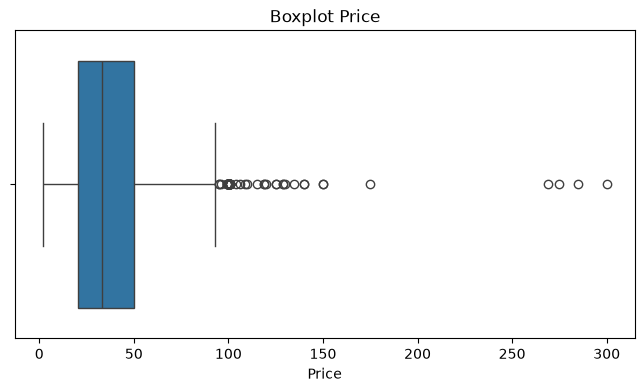

In [59]:
#Boxplot digunakan untuk mendeteksi adanya data outlier karena berbasis iqr
plt.figure(figsize=(8, 4)) #menentukan besar grafik

sns.boxplot(x=df["price"]) #membuat boxplot sesuai data pada kolom price

plt.title("Boxplot Price") #membuat text title
plt.xlabel("Price") # menentukan labeling 
plt.show() #memunculkan hasil boxplot

Secara visual dapat dilihat bahwa banyak data yang terdeteksi outlier oleh boxplot

In [60]:
Q1 = df["price"].quantile(0.25) #menentukan titik q1 (25%)
Q3 = df["price"].quantile(0.75) #menentukan titik q3 (75%)

IQR = Q3 - Q1 #rumus iqr adalah membaca rentang dari q3 ke q1

lower_bound = Q1 - (1.5 * IQR) #jika data 1.5 kali lipat lebih kecil dari q1 maka outlier
upper_bound = Q3 + (1.5 * IQR) #jika data 1.5 kali lipat lebih besar dari q3 maka outlier

print("Q1          :", Q1)
print("Q3          :", Q3)
print("IQR         :", IQR)
print("Batas Bawah :", lower_bound)
print("Batas Atas :", upper_bound)

Q1          : 20.69
Q3          : 49.99
IQR         : 29.3
Batas Bawah : -23.26
Batas Atas : 93.94


In [61]:
outlier_price = df[(df["price"] < lower_bound) |(df["price"] > upper_bound)] #mengumpulkan data yang melewati batas atas dan bawah

print("Jumlah Outlier Price:", len(outlier_price)) #len digunakan untuk mendeteksi jumlah data yang masuk criteria outlier

Jumlah Outlier Price: 52


Penjelasan :

Berdasarkan Metode IQR diperoleh nilai Q1 sebesar 20.69, Q3 sebesar 49.99, dan IQR sebesar 29,3. Berdasarkan hasil perhitungan tersebut batas atas outlier adalah 93.94, sedangkan batas bawah -23.26 (tapi price tidak bisa minus)

Setelah dilakukan pengecekan data yang melewati batas terdapat 52 data yang terdeteksi sebagai outlier.

Walaupun setelah dicheck terdeteksi sebagai outlier, namun saya memutuskan untuk sementara tidak menghapus data tersebut, karena secara bentuk data, sangat mungkin terdapat beberapa produk parfum yang memiliki harga yang jauh lebih tinggi dibanding rata-rata parfume yang beredar di pasaran.

### Outlier Available

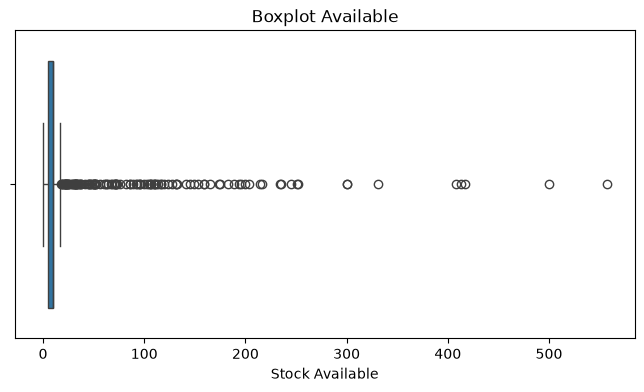

In [62]:
#penggunaan rumus sama persis dengan penanganan outlier kolom price
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["available"])

plt.title("Boxplot Available")
plt.xlabel("Stock Available")
plt.show()

Dibandingkan kolom price, terlihat jumlah outlier jauh lebih extreme.

In [63]:
Q1 = df["available"].quantile(0.25)
Q3 = df["available"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1          :", Q1)
print("Q3          :", Q3)
print("IQR         :", IQR)
print("Batas Bawah :", lower_bound)
print("Batas Atas  :", upper_bound)

Q1          : 5.0
Q3          : 10.0
IQR         : 5.0
Batas Bawah : -2.5
Batas Atas  : 17.5


In [64]:
outlier_available = df[(df["available"] < lower_bound) |(df["available"] > upper_bound)]

print("Jumlah Outlier available:", len(outlier_available))

Jumlah Outlier available: 120


Penjelasan :

Sama seperti pada kolom price, terdeteksi 120 data yang dianggap outlier secara statistik. batas atas yang didapatkan adalah 17.5 yang menunjukan bahwa mayoritas data memang memiliki rentang stock sekitar 5-10 unit. Namun, dari segi bisnis parfum, sangat mungkin bahwa beberapa brand memiliki stock bahkan sampai 500 unit jika memiliki skala produksi yang massive dan gudang yang cukup.

Jadi saya memutuskan untuk tetap mempertahankan data outlier pada kolom available.

### Outlier Sold

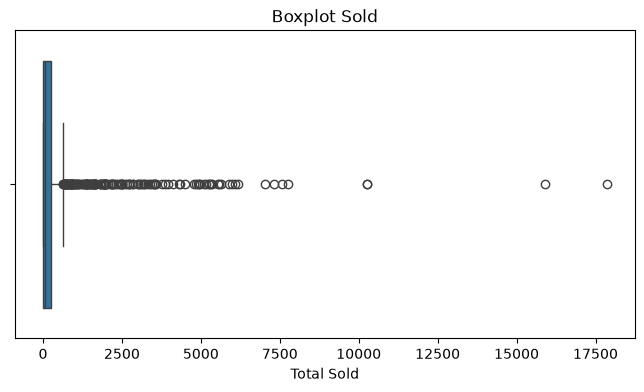

In [65]:
#penggunaan rumus sama persis dengan penanganan outlier kolom price & available
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["sold"])

plt.title("Boxplot Sold")
plt.xlabel("Total Sold")
plt.show()

Dari Boxplot terlihat outlier lebih extreme dibanding price & available.

In [66]:
Q1 = df["sold"].quantile(0.25)
Q3 = df["sold"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1          :", Q1)
print("Q3          :", Q3)
print("IQR         :", IQR)
print("Batas Bawah :", lower_bound)
print("Batas Atas  :", upper_bound)

Q1          : 15.0
Q3          : 257.0
IQR         : 242.0
Batas Bawah : -348.0
Batas Atas  : 620.0


In [67]:
outlier_sold = df[
    (df["sold"] < lower_bound) |
    (df["sold"] > upper_bound)
]

print("Jumlah Outlier Sold:", len(outlier_sold))

Jumlah Outlier Sold: 148


Penjelasan :

Sama seperti pada kolom price & available, terdeteksi 148 data yang dianggap outlier secara statistik. batas atas yang didapatkan adalah 620 yang menunjukan bahwa mayoritas data memang memiliki rentang penjualan sekitar 15-257 unit. Namun, dari segi bisnis parfum, sangat mungkin bahwa beberapa brand memiliki penjualan bahkan sampai 17.500 unit jika memiliki popularitas yang sangat tinggi.

Jadi saya memutuskan untuk tetap mempertahankan data outlier pada kolom sold.

### Outlier Summary

Deteksi Outlier dilakukan dengan metode IQR dan visualisasi dari Boxplot, dilakukan pada kolom numerik yaitu price,available,dan sold.

Ditemukan outlier secara statistik :
- 52 outlier pada price
- 120 outlier pada available
- 148 outlier pada sold

Namun, walaupun terdeteksi sebagai outlier, secara industry bisnis parfum data-data extreme tersebut sangat mungkin terjadi secara real. jadi saya memutuskan untuk t mempertahankan data tersebut, agar tidak ada informasi penting yang hilang pada saat data digunakan untuk analisa.

## Data Type

In [68]:
print(df.dtypes)

brand                    str
title                    str
type                     str
price                float64
priceWithCurrency        str
available            float64
availableText            str
sold                 float64
lastUpdated              str
itemLocation             str
InputNotes               str
dtype: object


In [69]:
df.info()

<class 'pandas.DataFrame'>
Index: 999 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              999 non-null    str    
 1   title              999 non-null    str    
 2   type               999 non-null    str    
 3   price              999 non-null    float64
 4   priceWithCurrency  999 non-null    str    
 5   available          999 non-null    float64
 6   availableText      991 non-null    str    
 7   sold               999 non-null    float64
 8   lastUpdated        927 non-null    str    
 9   itemLocation       999 non-null    str    
 10  InputNotes         999 non-null    str    
dtypes: float64(3), str(8)
memory usage: 277.2 KB


Dari bentuk data yang terbaca dengan query d.types dan df.info, bentuk data pada setiap kolom sudah sesuai kecuali available dan sold yang akan diubah menjadi integer, dan lastUpdate karena berisi tanggal. Maka dari itu akan dilakukan pengecekan lebih lanjut terhadap kolom tersebut.

In [70]:
#mengubah type data menjadi integer
df["available"] = df["available"].astype(int)
df["sold"] = df["sold"].astype(int)

In [71]:
display(df["lastUpdated"].head(20))

0     May 23, 2024 10:43:50 PDT
1     May 24, 2024 00:15:48 PDT
2     May 14, 2024 20:54:25 PDT
3     May 23, 2024 01:23:05 PDT
4                           NaN
5     May 23, 2024 10:44:09 PDT
6     May 24, 2024 00:15:13 PDT
7     May 21, 2024 06:41:13 PDT
8     May 23, 2024 22:39:02 PDT
9     May 24, 2024 00:25:04 PDT
10    May 24, 2024 11:01:13 PDT
11    May 24, 2024 11:01:04 PDT
12    May 23, 2024 16:56:32 PDT
13    May 22, 2024 10:25:36 PDT
14    May 08, 2024 09:46:06 PDT
15    May 24, 2024 09:43:51 PDT
16    May 24, 2024 10:21:14 PDT
17    May 22, 2024 18:32:01 PDT
18    May 23, 2024 01:10:19 PDT
19    Apr 05, 2024 00:52:19 PDT
Name: lastUpdated, dtype: str

In [72]:
print("Jumlah Unique Last Updated:", df["lastUpdated"].nunique())

Jumlah Unique Last Updated: 911


Format Datetime tidak bisa terbaca karena ada timezone dibelakang tanggal, maka dari itu saya akan mencoba menghapus timezonenya terlebih dahulu

In [73]:
#menggunakan query Regex untuk mendeteksi pola timezone pada data lastupdate
'''
r = menentukan nilai text dalam "" adalah rawstring sehingga backslash \ dibaca sebagai pola regex
\s+ = spasi
[A-Z] = huruf kapital A sampai Z
{3} = tepat 3 huruf
$ = harus berada di akhir text
'''
df["lastUpdated"] = (df["lastUpdated"].str.replace(r"\s+[A-Z]{3}$", "", regex=True))

display(df["lastUpdated"].head(10))

0    May 23, 2024 10:43:50
1    May 24, 2024 00:15:48
2    May 14, 2024 20:54:25
3    May 23, 2024 01:23:05
4                      NaN
5    May 23, 2024 10:44:09
6    May 24, 2024 00:15:13
7    May 21, 2024 06:41:13
8    May 23, 2024 22:39:02
9    May 24, 2024 00:25:04
Name: lastUpdated, dtype: str

In [74]:
''' 
errors="coerce" digunakan aga jika ada error data akan didefinisikan sebagai NaT (Not a Time)
format = "mixed" agar lebih fleksible jika ada perbedaan format tanggal
'''

df["lastUpdated"] = pd.to_datetime(df["lastUpdated"],format="mixed",errors="coerce") #mengkonversi data menjadi datetime menggunakan pd.to_datetime

Setelah melakukan konversi, saya akan coba check kembali menggunakan dtypes dan df.info

In [75]:
print(df.dtypes)

brand                           str
title                           str
type                            str
price                       float64
priceWithCurrency               str
available                     int64
availableText                   str
sold                          int64
lastUpdated          datetime64[us]
itemLocation                    str
InputNotes                      str
dtype: object


In [76]:
df.info()

<class 'pandas.DataFrame'>
Index: 999 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   brand              999 non-null    str           
 1   title              999 non-null    str           
 2   type               999 non-null    str           
 3   price              999 non-null    float64       
 4   priceWithCurrency  999 non-null    str           
 5   available          999 non-null    int64         
 6   availableText      991 non-null    str           
 7   sold               999 non-null    int64         
 8   lastUpdated        927 non-null    datetime64[us]
 9   itemLocation       999 non-null    str           
 10  InputNotes         999 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(2), str(7)
memory usage: 254.5 KB


### Summary type data

Penjelasan :
dari seluruh kolom yang ada, hanya ada 3 kolom yang secara dtypes memiliki bentuk data yang salah, yaitu available, sold dan lastUpdate.

Untuk kolom available dan sold, pengubahan dari float ke integer dapat dilakukan secara langsung

Untuk kolom lastUpdate awalnya memiliki data string, meskipun berisi informasi tanggal dan waktu. Agar mempermudah konversi ke datetime saya menghabus timezone menggunakann regex.

Setelah selesai, data dikonversi menjadi datetime menggunakan pd.to_datetime() dengan format="mixed" agar dapat mendeteksi beberapa pola tanggal, dan errors="coerce" agar dapat mendeteksi pola yang tidak bisa dikonversi menjadi datetime, dan mengubahnya menjadi NaT (Not a Time)

terlihat dari df.info terakhir, format sudah berhasil diubah menjadi dattetime64[us]

## Konsistensi Data

In [77]:
type_counts = df["type"].value_counts()

display(type_counts)

type
Eau de Parfum            563
Eau de Toilette          186
Perfume                   55
Eau de Cologne            37
Eau de Perfume            23
                        ... 
Pink Sugar                 1
Oil Perfume                1
FRAGRANCE BODY MIST        1
Eau de Parfum/Perfume      1
1                          1
Name: count, Length: 71, dtype: int64

In [78]:
brand_counts = df["brand"].value_counts()

display(brand_counts)

brand
Lancôme                      37
Versace                      34
Dolce&Gabbana                30
Jo Malone                    29
Carolina Herrera             27
                             ..
DKNY                          1
United Colors of Benetton     1
Maison                        1
Vince Camuto                  1
Juliette Has A Gun            1
Name: count, Length: 247, dtype: int64

In [79]:
location_counts = df["itemLocation"].value_counts()

display(location_counts)

itemLocation
Dallas, Texas, United States              141
Hackensack, New Jersey, United States      85
Brooklyn, New York, United States          35
Miami, Florida, United States              32
Edison, New Jersey, United States          26
                                         ... 
Battle Creek, Michigan, United States       1
Chino, California, United States            1
Mount Holly, New Jersey, United States      1
Lodi, California, United States             1
Poway, California, United States            1
Name: count, Length: 299, dtype: int64

Dari 3 kolom kategorikal yang dapat terlihat secara pasti ada kemiripan adalah kolom type. maka dari itu saya akan melakukan penanganan pada kolom type terlebih dahulu

In [80]:
#sebelum itu kita coba bersihkan spasi di awal dan akhir dari data pada kolom kategorikal terlebih dahulu
text_columns = ["brand", "type", "itemLocation"] #mengelompokan kolom yang berisi teks atau berbentuk kategorikal

for col in text_columns:
    df[col] = df[col].str.strip() #menghapus spasi dengan .str.strip

### Konsistensi Kolom Type

In [81]:
print("Jumlah Unique Type:", df["type"].nunique()) #cek unique pada kolom type
display(df["type"].value_counts().head(30)) #karena terlalu banyak kita coba munculkan 30 baris unique terlebih dahulu

Jumlah Unique Type: 71


type
Eau de Parfum                                   563
Eau de Toilette                                 186
Perfume                                          55
Eau de Cologne                                   37
Eau de Perfume                                   23
Eau De Parfum                                    16
Fragrances                                       14
Fragrance Mist                                   11
Eau de Toilette, Spray                            6
Eau De Toilette                                   6
Spray                                             5
Gift Sets                                         4
Lotion                                            4
Parfum                                            3
Extrait de Parfum                                 3
Perfume Oil                                       3
Perfume, Eau de Parfum                            2
Eau de Parfume                                    2
SKIN_MOISTURIZER                                  2
cologne

In [82]:
#membuat dictionary supaya tidak perlu melakukan replace satu persatu
type_dict = {
    "Eau De Parfum": "Eau de Parfum",
    "Eau de Perfume": "Eau de Parfum",
    "Eau de Parfume": "Eau de Parfum",
    "Eau De Toilette": "Eau de Toilette"
}

df["type"] = df["type"].replace(type_dict) #replace sesuai dictionary

In [83]:
print("Jumlah Unique Type Setelah Cleaning:", df["type"].nunique())

display(df["type"].value_counts().head(30))

Jumlah Unique Type Setelah Cleaning: 67


type
Eau de Parfum                                   604
Eau de Toilette                                 192
Perfume                                          55
Eau de Cologne                                   37
Fragrances                                       14
Fragrance Mist                                   11
Eau de Toilette, Spray                            6
Spray                                             5
Gift Sets                                         4
Lotion                                            4
Parfum                                            3
Extrait de Parfum                                 3
Perfume Oil                                       3
Perfume, Eau de Parfum                            2
SKIN_MOISTURIZER                                  2
cologne                                           2
Esprit de Parfum                                  2
~ BODY FIRM ADVANCED BODY REPAIR TREATMENT ~      1
Deodorant Stick                                   1
3 Pc   

In [84]:
#export data menjadi excel supaya AI bisa bantu bikin dictionary untuk replace data yang memiliki arti yang sama
df.to_excel("perfume_cleaning.xlsx", index=False) 

In [85]:
#dictionary dibuat oleh AI untuk mempercepat proses
type_dict = {
    # Eau de Parfum
    "/": "Eau de Parfum",
    "1": "Eau de Parfum",
    "BEAUTY": "Eau de Parfum",
    "EDP": "Eau de Parfum",
    "Eau de Parfum, Eau De Parfume": "Eau de Parfum",
    "Eau de Parfum, Spray": "Eau de Parfum",
    "Eau de Parfum/Perfume": "Eau de Parfum",
    "Perfume, Eau de Parfum": "Eau de Parfum",
    "Eau De Parfum Supreme": "Eau de Parfum",

    # Eau de Toilette
    "EDT": "Eau de Toilette",
    "Toilette Spray": "Eau de Toilette",
    "Eau de Toilette, Spray": "Eau de Toilette",
    "Eau De Toilette Spray 3.4 oz": "Eau de Toilette",

    # Eau de Cologne
    "cologne": "Eau de Cologne",
    "Cologne": "Eau de Cologne",
    "Cologne Spray": "Eau de Cologne",
    "Eau De Cologne": "Eau de Cologne",

    # Fragrance / Body Mist
    "FRAGRANCE BODY MIST": "Fragrance Mist",
    "Fine Fragrance Mist": "Fragrance Mist",
    "Perfume Fragrance Mist": "Fragrance Mist",
    "Mist": "Fragrance Mist",

    # Oils
    "Oil Perfume": "Perfume Oil",
    "Scented Oils": "Perfume Oil",

    # Lotion / Moisturizer
    "Body Lotion": "Lotion",
    "SKIN_MOISTURIZER": "Lotion",
    "Sensuous Body Moisturizer": "Lotion",

    # Deodorant
    "deodorant": "Deodorant",
    "Deodorant Stick": "Deodorant",

    # Gift / Set
    "3 Pc": "Gift Sets",
    "Perfume Gift Sets": "Gift Sets",
    "Discovery Set": "Gift Sets"
}

df["type"] = df["type"].replace(type_dict)

In [86]:
print("Jumlah Unique Type Setelah Cleaning:", df["type"].nunique())

display(df["type"].value_counts())

Jumlah Unique Type Setelah Cleaning: 37


type
Eau de Parfum                                   614
Eau de Toilette                                 201
Perfume                                          55
Eau de Cologne                                   42
Fragrance Mist                                   15
Fragrances                                       14
Lotion                                            8
Gift Sets                                         7
Spray                                             5
Perfume Oil                                       5
Parfum                                            3
Extrait de Parfum                                 3
Deodorant                                         2
Esprit de Parfum                                  2
~ BODY FIRM ADVANCED BODY REPAIR TREATMENT ~      1
Body Spray                                        1
Hair Perfume                                      1
Cream                                             1
Eau De Parfum 2 Pcs Set                           1
L'Eau d

In [87]:
#deteksi kembali data yang masih bisa dikelompokan
type_dict_3 = {
    "L'Eau de Parfum": "Eau de Parfum",
    "L'eau de Parfum": "Eau de Parfum",
    "EDP and Parfum": "Eau de Parfum",
    "Eau De Parfum 2 Pcs Set": "Eau de Parfum",
    "Eau De Parfum 3 Pcs Set": "Eau de Parfum",
    "Eau De Parfum Spray (Unisex Tester) 3.4 oz": "Eau de Parfum",
    "SOLID PERFUME STICK": "Perfume",
    "Does not Apply": "Unknown",
    "Does Not Apply": "Unknown",
    "Parfum" : "Perfume"
}

df["type"] = df["type"].replace(type_dict_3)

In [88]:
print("Jumlah Unique Type Setelah Cleaning:", df["type"].nunique())

display(df["type"].value_counts())

Jumlah Unique Type Setelah Cleaning: 29


type
Eau de Parfum                                   620
Eau de Toilette                                 201
Perfume                                          59
Eau de Cologne                                   42
Fragrance Mist                                   15
Fragrances                                       14
Lotion                                            8
Gift Sets                                         7
Spray                                             5
Perfume Oil                                       5
Extrait de Parfum                                 3
Deodorant                                         2
Esprit de Parfum                                  2
~ BODY FIRM ADVANCED BODY REPAIR TREATMENT ~      1
Body Spray                                        1
Hair Perfume                                      1
Cream                                             1
Does not apply                                    1
Shimmer                                           1
Parfum,

Penjelasan : 

Pada kolom type awalnya ada 71 kategori unik yang berisi beberapa data yang memiliki makna yang sama, setelah dikonversi dengan .replace, tersisa 29 kategori unique.

sisa data yang memiliki arti produk berbeda dan memiliki arti yang tidak pasti tetap dipertahankan agar tidak terlalu mengubah arti dari data aslinya.

### Konsistensi Kolom Brand

In [89]:
print("Jumlah Unique Brand:", df["brand"].nunique())

display(df["brand"].value_counts().head(30))

Jumlah Unique Brand: 247


brand
Lancôme               37
Versace               34
Dolce&Gabbana         30
Jo Malone             29
Carolina Herrera      27
Victoria's Secret     26
Yves Saint Laurent    25
Ariana Grande         25
Burberry              21
Parfums de Marly      19
Thierry Mugler        18
Calvin Klein          17
Gucci                 16
Coach                 15
AS SHOWN              15
Marc Jacobs           14
Dolce & Gabbana       13
Juicy Couture         13
Dossier               13
Jimmy Choo            13
Givenchy              13
As Show               12
Lattafa               12
Kilian                12
Elizabeth Arden       12
Estée Lauder          12
Giorgio Armani        12
PRADA                 11
Unbranded             11
Clinique              11
Name: count, dtype: int64

In [90]:
#penanganan yang sama seperti kolom type
brand_dict = {
    # Al Rehab
    "Al-Rehab": "Al Rehab",

    # Alfred Sung
    "ALFRED SUNG": "Alfred Sung",

    # Burberry
    "BURBERRY": "Burberry",

    # Byredo
    "BYREDO": "Byredo",

    # Chloe
    "Chloe": "Chloé",

    # Dolce & Gabbana
    "Dolce Gabbana": "Dolce & Gabbana",
    "Dolce&Gabbana": "Dolce & Gabbana",

    # Dossier
    "dossier": "Dossier",

    # Escada
    "ESCADA": "Escada",

    # Estee Lauder
    "Estee Lauder": "Estée Lauder",

    # Giorgio Armani
    "Giorgi^o Armani": "Giorgio Armani",
    "Giorgio Arm.ani": "Giorgio Armani",
    "Giorgio² Armani": "Giorgio Armani",

    # Giorgio Beverly Hills
    "GIORGIO BEVERLY HILLS": "Giorgio Beverly Hills",

    # Jennifer Lopez
    "J Lo": "Jennifer Lopez",
    "JLO": "Jennifer Lopez",

    # Juliette Has A Gun
    "Juliette has a gun": "Juliette Has A Gun",
    "Juliette Has a Gun": "Juliette Has A Gun",

    # Kate Spade
    "Kate Spade New York": "Kate Spade",

    # Lancôme
    "LANCOME": "Lancôme",
    "Lancome": "Lancôme",

    # Lattafa
    "Lattafa Perfumes": "Lattafa",

    # Maison Margiela
    "Maison Martin Margiela": "Maison Margiela",

    # Montale
    "MONTALE": "Montale",

    # Parfums Grès
    "Parfums Gres": "Parfums Grès",

    # Yves Saint Laurent
    "YSL": "Yves Saint Laurent"
}

df["brand"] = df["brand"].replace(brand_dict)

In [91]:
print("Unique Brand Sebelum Cleaning : 247")
print("Unique Brand Setelah Cleaning :", df["brand"].nunique())

display(df["brand"].value_counts().head(30))

Unique Brand Sebelum Cleaning : 247
Unique Brand Setelah Cleaning : 221


brand
Dolce & Gabbana       44
Lancôme               41
Versace               34
Jo Malone             29
Carolina Herrera      27
Yves Saint Laurent    27
Victoria's Secret     26
Ariana Grande         25
Burberry              22
Parfums de Marly      19
Giorgio Armani        18
Thierry Mugler        18
Calvin Klein          17
Gucci                 16
Coach                 15
AS SHOWN              15
Marc Jacobs           14
Dossier               14
Lattafa               13
Juicy Couture         13
Estée Lauder          13
Jimmy Choo            13
Givenchy              13
As Show               12
Juliette Has A Gun    12
Kilian                12
Elizabeth Arden       12
PRADA                 11
Unbranded             11
Clinique              11
Name: count, dtype: int64

Penjelasan : 

Pada kolom brand awalnya ada 247 kategori unik yang berisi beberapa data yang memiliki makna yang sama, setelah dikonversi dengan .replace, tersisa 221 kategori unique.

sisa data yang memiliki arti produk berbeda dan memiliki arti yang tidak pasti tetap dipertahankan agar tidak terlalu mengubah arti dari data aslinya.

### Konsistensi Kolom Location

In [92]:
print("Jumlah Unique Item Location:", df["itemLocation"].nunique())

display(df["itemLocation"].value_counts().head(30))

Jumlah Unique Item Location: 299


itemLocation
Dallas, Texas, United States                  141
Hackensack, New Jersey, United States          85
Brooklyn, New York, United States              35
Miami, Florida, United States                  32
Edison, New Jersey, United States              26
Detroit, Michigan, United States               25
Las Vegas, Nevada, United States               23
New York, New York, United States              19
Houston, Texas, United States                  19
Warren, Michigan, United States                18
Hamtramck, Michigan, United States             16
Los Angeles, California, United States         15
Katy, Texas, United States                     15
College Point, New York, United States         14
Albany, New York, United States                 9
Ecorse, Michigan, United States                 8
Dearborn Heights, Michigan, United States       8
Long Island City, New York, United States       8
TX, United States                               8
Jamaica, New York, United States     

In [93]:
df["itemLocation"] = df["itemLocation"].str.strip() #penghapusan spasi agar tidak terbaca sebagai unique berbeda

In [94]:
print("Jumlah Unique Item Location:", df["itemLocation"].nunique())

display(df["itemLocation"].value_counts().head(30))

Jumlah Unique Item Location: 299


itemLocation
Dallas, Texas, United States                  141
Hackensack, New Jersey, United States          85
Brooklyn, New York, United States              35
Miami, Florida, United States                  32
Edison, New Jersey, United States              26
Detroit, Michigan, United States               25
Las Vegas, Nevada, United States               23
New York, New York, United States              19
Houston, Texas, United States                  19
Warren, Michigan, United States                18
Hamtramck, Michigan, United States             16
Los Angeles, California, United States         15
Katy, Texas, United States                     15
College Point, New York, United States         14
Albany, New York, United States                 9
Ecorse, Michigan, United States                 8
Dearborn Heights, Michigan, United States       8
Long Island City, New York, United States       8
TX, United States                               8
Jamaica, New York, United States     

Dari hasil pengecheckan data itemLocation, karena bentuk datanya adalah informasi lokasi, saya memutuskan untuk tidak merubah data tersebut, karena tidak ditemukan kesalahan format penulisan, saya menghindari pengubahan data karena tidak ada informasi tambahan dari kolom lain yang bisa dijadikan acuan.

## Distribution Check

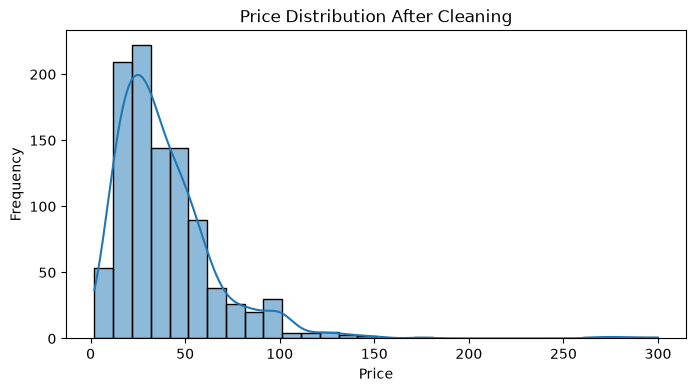

In [95]:
plt.figure(figsize=(8, 4))

sns.histplot(df["price"], bins=30, kde=True)

plt.title("Price Distribution After Cleaning")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

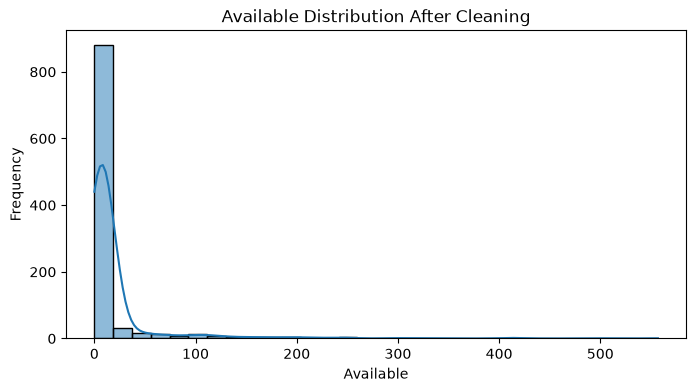

In [96]:
plt.figure(figsize=(8, 4))

sns.histplot(df["available"], bins=30, kde=True)

plt.title("Available Distribution After Cleaning")
plt.xlabel("Available")
plt.ylabel("Frequency")
plt.show()

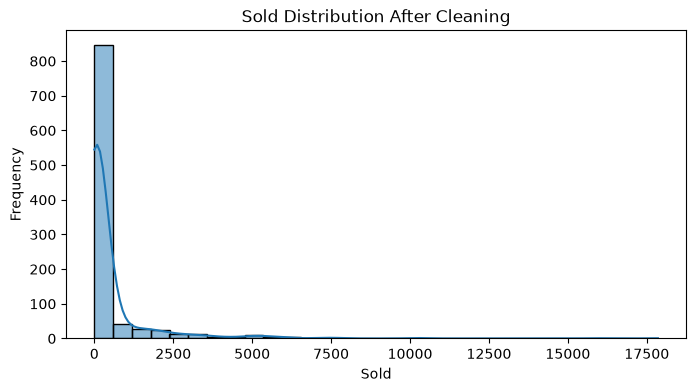

In [97]:
plt.figure(figsize=(8, 4))

sns.histplot(df["sold"], bins=30, kde=True)

plt.title("Sold Distribution After Cleaning")
plt.xlabel("Sold")
plt.ylabel("Frequency")
plt.show()

Setelah proses data cleaning, dilakukan pengecheckan kembali terhadap distribusi variable numerik, menggunakan histogram dan KDE Plot. Bisa dilihat bawhwa bentuk distribusi data dari kolom price,available, dan sold masih sama seperti awal pengecekan yaitu berbentuk right/positive skewed.

hal ini menunjukan bahwa mayoritas data berada pada nilai yang relatif rendah, sedangkan ada beberapa data yang memiliki nilai yang jauh lebih tinggi.

Walaupun memiliki nilai extreme, secara bisnis hal tersebut sangat wajar, karena bisa saja ada brand yang memiliki harga, stock available, dan penjualan yang jauh lebih tinggi dibanding mayoritas kompetitor.

yang sedikit berbeda hanya sedikit terjadi penumpukan pada nilai median, karena pengisian kolom missing value dengan nilai median.

## Data Cleaning Summary

In [98]:
print("Dataset Shape :", df.shape)
print("Duplicate Data :", df.duplicated().sum())

print("\nMissing Values:")
display(df.isnull().sum())

print("\nData Types:")
display(df.dtypes)

Dataset Shape : (999, 11)
Duplicate Data : 0

Missing Values:


brand                 0
title                 0
type                  0
price                 0
priceWithCurrency     0
available             0
availableText         8
sold                  0
lastUpdated          72
itemLocation          0
InputNotes            0
dtype: int64


Data Types:


brand                           str
title                           str
type                            str
price                       float64
priceWithCurrency               str
available                     int64
availableText                   str
sold                          int64
lastUpdated          datetime64[us]
itemLocation                    str
InputNotes                      str
dtype: object

Penjelasan :

Setelah proses data cleaning, dataset memiliki 999 baris dan 11 kolom. Data duplikat sudah tidak ditemukan. Missing value pada kolom numerik sudah berhasil ditangani, walaupun masih ada missing value sebanyak 8 data pada availableText dan 72 data pada lastUpdate, yang dipertahankan karena tidak adanya informasi pendukung untuk menentukan nilai yang bisa digunakan untuk mengisi data tersebut.Selain itu, kolom lastUpdate juga sudah berhasil dikonversikan menjadi datetime.

## Categorical Data Encoding & Outlier Detection (Rare Cateogry detection)

In [99]:
#cek kolom kategorikal
categorical_cols = df.select_dtypes(include=["object", "string", "category"]).columns #filter kolom kategorikal

print("Categorical Columns:")
print(categorical_cols)

Categorical Columns:
Index(['brand', 'title', 'type', 'priceWithCurrency', 'availableText',
       'itemLocation', 'InputNotes'],
      dtype='str')


In [100]:
#check unique values
for col in categorical_cols:
    print(f"{col} : {df[col].nunique()} unique values")

brand : 221 unique values
title : 975 unique values
type : 29 unique values
priceWithCurrency : 655 unique values
availableText : 746 unique values
itemLocation : 299 unique values
InputNotes : 4 unique values


In [101]:
#check frequency
for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


brand
brand
Dolce & Gabbana       44
Lancôme               41
Versace               34
Jo Malone             29
Carolina Herrera      27
Yves Saint Laurent    27
Victoria's Secret     26
Ariana Grande         25
Burberry              22
Parfums de Marly      19
Name: count, dtype: int64

title
title
Idole by Lancome Eau de Parfum EDP Perfume for Women 2.5 oz New in Box              4
Good Girl by Carolina Herrera 2.7 oz Eau De Parfum Spray Women's New & Sealed       3
Dolce & Gabbana Light Blue  3.3 oz / 3.4 oz EDT Spray for Women Brand New Sealed    3
PRADA Paradoxe by Prada EDP 3.0oz/90ml Spray Perfume for Women New In Box           2
Sì Passione by Giorgio Armani For Women 3.4 Oz Eau De Parfum Spray New in Box       2
Cloud by Ariana Grande 3.4 oz / 100 ML EDP Perfume for Women New In Box Sealed      2
Maison Margiela Replica Sailing Day Eau de Toilette 3.4 oz New in Box US            2
LIBRE By Yves Saint Laurent YSL Eau de Parfum EDP Perfume 3 Oz/90ML for Women       2
PRADA Para

In [102]:
df_encoded = df.copy()

In [103]:
categorical_analysis = ["brand", "type", "itemLocation"]

for col in categorical_analysis:
    frequency = df[col].value_counts()
    df_encoded[col + "_encoded"] = df[col].map(frequency)

display(df_encoded[
        ["brand", "brand_encoded",
         "type", "type_encoded",
         "itemLocation", 
         "itemLocation_encoded"]].head())

,brand,brand_encoded,type,type_encoded,itemLocation,itemLocation_encoded
0,Carolina Herrera,27,Eau de Parfum,620,"Thomasville, Alabama, United States",3
1,As Shown,2,Eau de Parfum,620,"New Jersey, Hong Kong",2
2,PRADA,11,Eau de Parfum,620,"Orange, New Jersey, United States",1
3,As Show,12,Eau de Parfum,620,"USA, New Jersey, Hong Kong",3
4,Khadlaj,3,Eau de Parfum,620,"Little Ferry, New Jersey, United States",1


In [104]:
for col in categorical_analysis:
    print(f"\n{col}")
    print(df[col].value_counts().sort_values().head(10))


brand
brand
QRC                  1
~ CREPE ERASE ~      1
EX NIHILO            1
Roja                 1
Urban Outfitters     1
AS  SHOWN            1
Gloria Vanderbilt    1
Parfums              1
Frederic Malle       1
Lake&skye            1
Name: count, dtype: int64

type
type
Hair Perfume                                    1
~ BODY FIRM ADVANCED BODY REPAIR TREATMENT ~    1
Body Spray                                      1
Pink Sugar                                      1
Body Powder                                     1
Shimmering Body Oil                             1
Unknown                                         1
Extract Parfum                                  1
ASST                                            1
Body Mist                                       1
Name: count, dtype: int64

itemLocation
itemLocation
Roseville, California, United States      1
Poway, California, United States          1
Lodi, California, United States           1
Mount Holly, New Jersey, United Sta

In [105]:
threshold = len(df) * 0.01

print("Rare Category Threshold :", threshold)

Rare Category Threshold : 9.99


In [106]:
for col in categorical_analysis:
    frequency = df[col].value_counts()
    rare_categories = frequency[frequency < threshold]

    print(f"\n{col}")
    print("Jumlah Rare Categories :", len(rare_categories))
    display(rare_categories)


brand
Jumlah Rare Categories : 189


brand
Donna Karan                  9
Narciso Rodriguez            9
Maison Alhambra              9
Ralph Lauren                 9
CHANEL                       9
                            ..
Armand Dupree Fuller         1
DKNY                         1
United Colors of Benetton    1
Maison                       1
Vince Camuto                 1
Name: count, Length: 189, dtype: int64


type
Jumlah Rare Categories : 23


type
Lotion                                          8
Gift Sets                                       7
Spray                                           5
Perfume Oil                                     5
Extrait de Parfum                               3
Deodorant                                       2
Esprit de Parfum                                2
~ BODY FIRM ADVANCED BODY REPAIR TREATMENT ~    1
Body Spray                                      1
Hair Perfume                                    1
Cream                                           1
Does not apply                                  1
Shimmer                                         1
Parfum, Lotion, Gloss and Blush                 1
Bath Oil                                        1
Elixir De Parfum                                1
Body Mist                                       1
ASST                                            1
Extract Parfum                                  1
Unknown                                      


itemLocation
Jumlah Rare Categories : 285


itemLocation
Albany, New York, United States              9
Ecorse, Michigan, United States              8
Dearborn Heights, Michigan, United States    8
Long Island City, New York, United States    8
TX, United States                            8
                                            ..
Battle Creek, Michigan, United States        1
Chino, California, United States             1
Mount Holly, New Jersey, United States       1
Lodi, California, United States              1
Poway, California, United States             1
Name: count, Length: 285, dtype: int64

Penjelasan :
Untuk data kategorikal, saya menggunakan frequency encoding. Dimana kategori yang merepresentasikan kurang dari 1% total data, ditentukan sebagai "Rare Category" atau kategori langka untuk di investigasi lebih lanjut. Pada tahap ini, rare category belum saya keluarkan dari dataset karena masih sangat memungkinkan menjadi data yang valid.

# Data Analysis

## Top 10 Best Selling Brand

In [107]:
top_brand_sold = (df.groupby("brand")["sold"].sum().sort_values(ascending=False).head(10))

display(top_brand_sold)

brand
Calvin Klein        48100
Versace             31561
Dolce & Gabbana     20745
Elizabeth Taylor    20649
Vera Wang           20308
Burberry            19179
Juicy Couture       14258
GUESS               13480
Jimmy Choo          12204
Alfred Sung         11451
Name: sold, dtype: int64

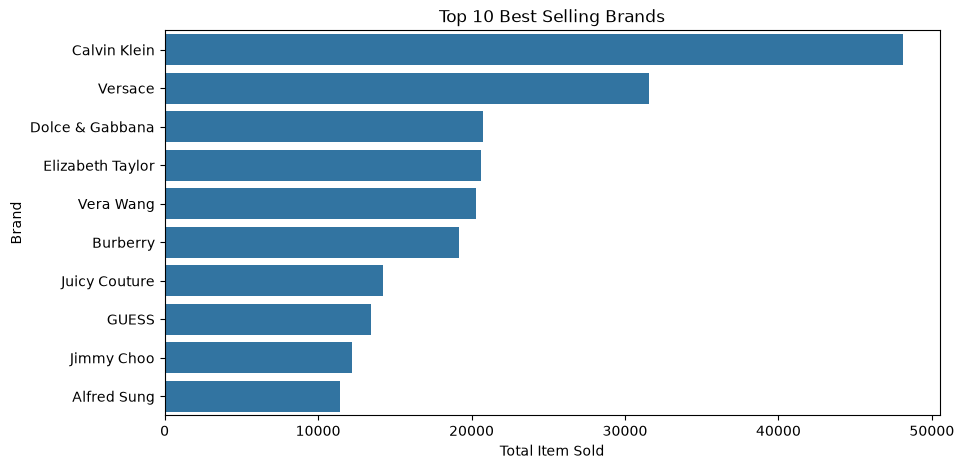

In [108]:
plt.figure(figsize=(10, 5))

sns.barplot(x=top_brand_sold.values,y=top_brand_sold.index)

plt.title("Top 10 Best Selling Brands")
plt.xlabel("Total Item Sold")
plt.ylabel("Brand")
plt.show()

In [109]:
top_product = (df.groupby("title")["sold"].sum().sort_values(ascending=False).head(10))

display(top_product)

title
Escape by Calvin Klein EDP Perfume for Women 3.4 oz New In Box                    17854
VERA WANG Perfume 3.3 / 3.4 oz EDP For Women Spray NEW IN BOX                     15897
VANDERBILT by Gloria 3.4 oz 3.3 edt for Women Perfume  New Box Seal               10268
White Diamonds by Elizabeth Taylor 3.3 3.4 oz EDT Perfume for Women New Tester    10259
RED by GIORGIO BEVERLY HILLS women edt spray Perfume 3.0 oz New                    7773
Guess Marciano perfume for women EDP 3.3 / 3.4 oz New in Box                       7558
Exclamation by Coty Perfume for Women Cologne Spray 1.7 oz New In Box              7331
Eternity by CK Calvin Klein 3.4 oz EDP Perfume for Women Tester                    7018
Brit Sheer by Burberry 3.3 / 3.4 oz EDT Perfume for Women New In Box               6946
360 by Perry Ellis Perfume 3.3 / 3.4 oz Spray for Women edt NEW IN BOX             6077
Name: sold, dtype: int64

Insight :

Berdasarkan jumlah produk terjual (sold), Calvin Klein adalah brand dengan total penjualan tertinggi, yaitu sebesar 48.100 unit. Diikuti Versace dengan penjualan 31.561 unit.

Dalam dataset Ebay ini Calvin Klein cukup mendominasi secara penjualan karena total penjualannya memiliki selisih cukup jauh dibandingkan brand lain.

Salah satu kontributor penjualan terbesar dari Brand Calvin Klein ada pada product "Escape by Calvin Klein EDP Parfume for Women 3.4 oz New in Box" yang menyumbang 17.854 penjualan Calvin Klein di Dataset Ebay ini.

## Price vs Sold Correlation

In [110]:
correlation = df["price"].corr(df["sold"])

print(f"Correlation between Price and Sold: {correlation:.2f}")

Correlation between Price and Sold: -0.14


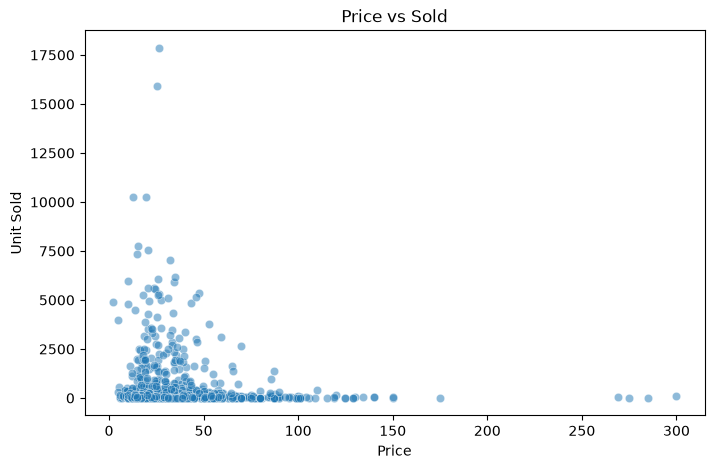

In [111]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df,x="price",y="sold",alpha=0.5)

plt.title("Price vs Sold")
plt.xlabel("Price")
plt.ylabel("Unit Sold")
plt.show()

Insight :

Dari hasil perhitungan korelasi dan visualisasi Scatter Plot, didapatkan hasil -0.14 yang menunjukan bahwa ada hubungan negatif yang lemah antara harga dan jumlah produk terjual. Dapat diintepretasikan bahwa semakin tinggi harga, akan menghasilkan penjualan yang cenderung lebih rendah, namun tidak signifikan.

## Top 10 Best Selling Product Types

In [112]:
top_type_sold = (df.groupby("type")["sold"].sum().sort_values(ascending=False).head(10))

display(top_type_sold)

type
Eau de Parfum        271299
Eau de Toilette      178215
Eau de Cologne        20874
Perfume               10208
Lotion                 2507
Body Powder            1454
Hair Perfume           1130
Fragrance Mist          995
Extrait de Parfum       689
Perfume Oil             618
Name: sold, dtype: int64

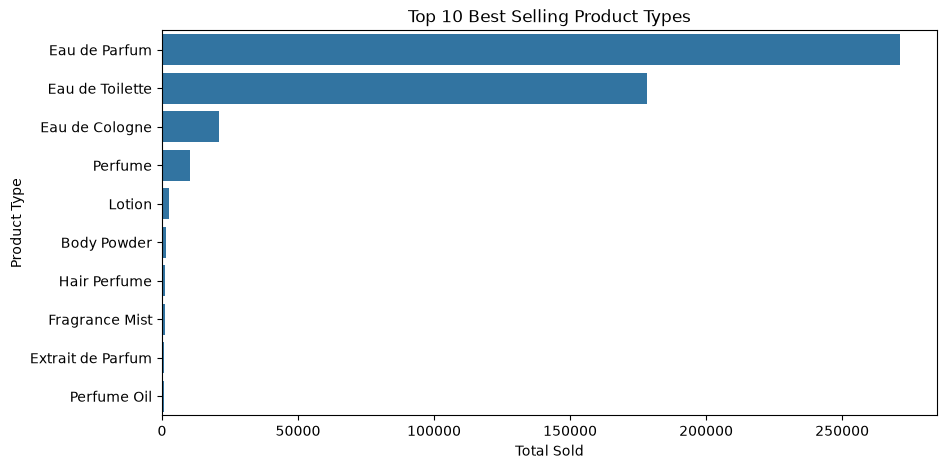

In [113]:
plt.figure(figsize=(10, 5))

sns.barplot(x=top_type_sold.values,y=top_type_sold.index)

plt.title("Top 10 Best Selling Product Types")
plt.xlabel("Total Sold")
plt.ylabel("Product Type")
plt.show()

Insight :

Berdasarkan total penjualan, Eau de parfum memiliki jumlah penjualan tertinggi sebesar 271.299 unit. disusul oleh eau de toilette sebesar 178.215 unit. Kedua kategory type produk tersebut cukup mendominasi dibandingkan tipe lainnya. Hal ini menunjukan bahwa cukup banyak brand yang menjual tipe produk tersebut, dan tipe tersebut cukup diminati oleh mayoritas pasar, berdasarkan dataset Ebay Parfum yang digunakan.

# Data Cleaning Project Conclusion

Data Cleaning :
- Setelah dilakukan cleaning, bentuk dataset menjadi 999 baris dan 11 kolom tanpa data duplikat
- Missing Value pada kolom data numerik sudah berhasil ditangani dengan informasi yang tersedia serta input median.
- Missing Value pada availableText dan lastUpdate yang tidak memiliki informasi pendukung tetap dipertahankan
- Inkonsistensi data pada kolom type dan brand sudah distandarisasi
- kolom available dan sold yang berbentuk float sudah dirapihkan menjadi bentuk integer
- kolom lastUpdate yang berbentuk string namun berisi tanggal sudah berhasil diubah menjadi tipe data datetime.
- Terdeteksi Outlier pada kolom price, available, dan sold. namun data tetap dipertahankan karena sangat mungkin terjadi dalam bisnis parfum.

Data Analisis :
- berdasarkan hasil analisis, Calvin Klein merupakan brand dengan penjualan tertinggi sebesar 48.100 unit, hal ini didukung oleh kontribusi Product "Escape by Calvin Klein" yang memiliki penjualan sebesar 17.854 unit.
- Hubungan korelasi price dan sold menunjukan korelasi negatif namun lemah (-0.14), sehingga semakin tinggi harga cenderung membuat penjualan lebih rendah, namun tidak signifikan.
- Berdasarkan tipe produk, Eau de Parfum memiliki total penjualan tertinggi sebesar 271.299 unit.

# Exploratory Data Analysis (EDA)

## Univariate Analysis

### Distributiion of Product Prices

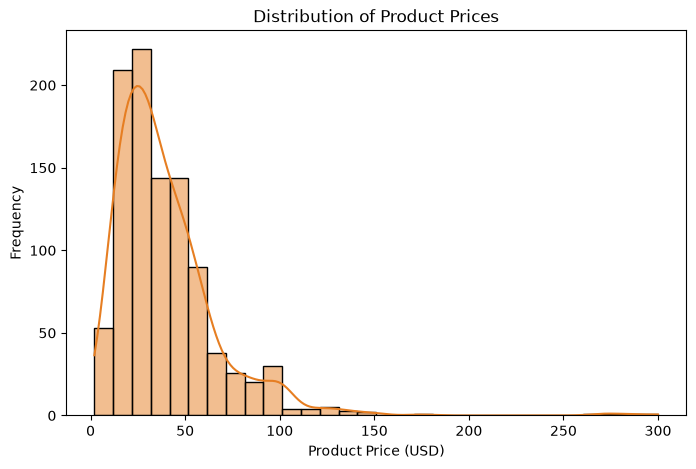

Mean Price   : 39.88
Median Price : 32.99
Max Price    : 299.99


In [114]:
plt.figure(figsize=(8, 5)) #menentukan besar area canvas

sns.histplot( #fungsi seaborn untuk membuat histogram
    data=df, #menggunakan data df
    x="price", # x pada kolom price
    bins=30, # menentukan jumlah bar
    kde=True, # menambahkan kdeplot dalam grafik
    color="#E67E22"
)

plt.title("Distribution of Product Prices") #membuat judul
plt.xlabel("Product Price (USD)") # membuat label / keterangan pada x
plt.ylabel("Frequency") # membuat lable / keterangan pada y (merupakan jumlah data dari price)
plt.show()

print("Mean Price   :", round(df["price"].mean(), 2)) # menghitung mean kolom price
print("Median Price :", round(df["price"].median(), 2)) # menghitung median kolom price
print("Max Price    :", round(df["price"].max(), 2)) # menghitung max kolom price

Penjelasan :

Sesuai dengan pengecekan awal, dan insight dari data cleaning, bisa dilihat bahwa distribusi jumlah harga produk menunjukkan pola right-skewed, dimana mayoritas produk memiliki harga produk yang relatif rendah pada rentang 15 - 60 dollar, sementara terdapat beberapa produk dengan jumlah harga yang jauh lebih tinggi bahkan mencapai 300 dollar.

Nilai mean yang lebih besar dari median menunjukkan bahwa beberapa produk dengan harga tinggi tersebut membuat rata-rata harga menjadi lebih tinggi dibanding mediannya.

### Distribution of Product Sold

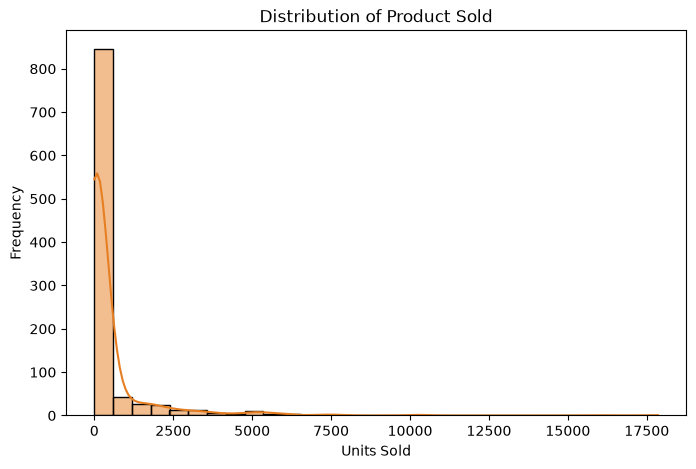

Mean Sold   : 490.64
Median Sold : 52.0
Max Sold    : 17854


In [115]:
plt.figure(figsize=(8,5)) #menentukan besar area canvas

sns.histplot( # fungsi seaborn untuk membuat histogram
    data=df, # menggunakan data df
    x="sold", # x pada kolom sold
    bins=30, # menentukan jumlah bar
    kde=True, # menambahkan kdeplot dalam grafik
    color="#E67E22"
)

plt.title("Distribution of Product Sold") #membuat judul
plt.xlabel("Units Sold") # membuat label / keterangan pada x
plt.ylabel("Frequency") # membuat lable / keterangan pada y (merupakan jumlah data dari sold)
plt.show()

print("Mean Sold   :", round(df["sold"].mean(),2)) # menghitung mean kolom sold
print("Median Sold :", round(df["sold"].median(),2)) # menghitung median kolom sold
print("Max Sold    :", round(df["sold"].max(),2)) # menghitung max kolom sold

Penjelasan :

Sesuai dengan pengecekan awal, dan insight dari data cleaning, bisa dilihat bahwa distribusi jumlah produk terjual menunjukkan pola right-skewed, dimana mayoritas produk memiliki jumlah penjualan yang relatif rendah, sementara terdapat beberapa produk dengan jumlah penjualan yang jauh lebih tinggi bahkan mencapai 17.854 item.

Nilai mean yang lebih besar dari median menunjukkan bahwa beberapa produk dengan penjualan sangat tinggi tersebut membuat rata-rata penjualan menjadi lebih tinggi dibanding mediannya. 

### Boxplot of product prices

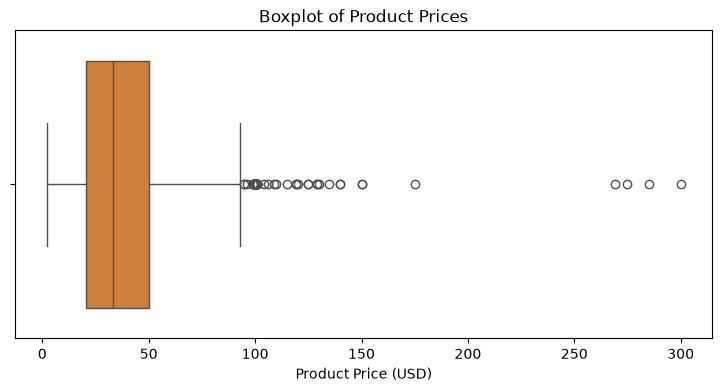

In [116]:
plt.figure(figsize=(9, 4)) # menentukan besar area canvas

sns.boxplot( # Fungsi Seaborn untuk membuat boxplot
    data=df, # menggunakan data pada df
    x="price", # menentukan kolom price sebagai x
    color="#E67E22" # menentukan warna boxplot
)

plt.title("Boxplot of Product Prices") # menentukan judul
plt.xlabel("Product Price (USD)") # menentukan keterangan pada x
plt.show() # memunculkan grafik

Penjelasan :

Pada grafik Boxplot yang telah dibuat, dapat dilihat bahwa sebagian besar harga produk berada pada kisaran sekitar USD 20–50, dengan median sebesar USD 32.99. Produk dengan harga sekitar 95 dollar ke atas teridentifikasi sebagai outliers. Beberapa produk bahkan memiliki harga ekstrem hingga mencapai sekitar 300 dollar.

Walaupun terdeteksi outlier, data tersebut tidak langsung dihapus karena secara bisnis masih dapat merepresentasikan produk parfum yang premium atau kemasan yang lebih besar.

### Boxplot of Product Sold

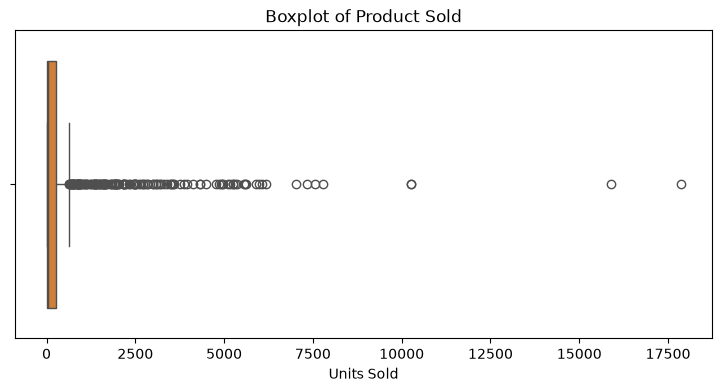

In [117]:
plt.figure(figsize=(9, 4)) # menentukan besar area canvas

sns.boxplot( # Fungsi Seaborn untuk membuat boxplot
    data=df, # menggunakan data pada df
    x="sold", # menentukan kolom price sebagai x
    color="#E67E22" # menentukan warna boxplot
)

plt.title("Boxplot of Product Sold") # menentukan judul
plt.xlabel("Units Sold") # menentukan keterangan pada x
plt.show() # memunculkan grafik

In [118]:
df.describe()

,price,available,sold,lastUpdated
count,999.000000,999.000000,999.000000,927
mean,39.884865,19.325325,490.636637,2024-05-15 14:00:38.570657
min,1.990000,0.000000,1.000000,2023-07-22 17:43:51
25%,20.690000,5.000000,15.000000,2024-05-16 12:20:20
50%,32.990000,10.000000,52.000000,2024-05-22 07:44:52
75%,49.990000,10.000000,257.000000,2024-05-23 21:05:20
max,299.990000,557.000000,17854.000000,2024-05-24 11:16:44
std,29.085615,48.362145,1363.233563,NaN


Penjelasan :

Pada grafik Boxplot yang telah dibuat, dapat dilihat bahwa sebagian besar produk memiliki penjualan yang cenderung rendahn pada rentang 15-257 unit, dan dengan median sebesar 52 unit.

Terdapat cukup banyak outliers yang terdeteksi dari box plot dengan jumlah penjualan yang jauh lebih tinggi dibandingkan mayoritas produk. Bahkan terdapat nilai extreem yang mencapai sekitar 17.500. 

Walaupun terdeteksi outlier, data tersebut tidak langsung dihapus karena secara bisnis masih dapat merepresentasikan produk parfum yang memang favorit dan diminati sebagian besar pasar.

### Top 10 Most Listed Product Types

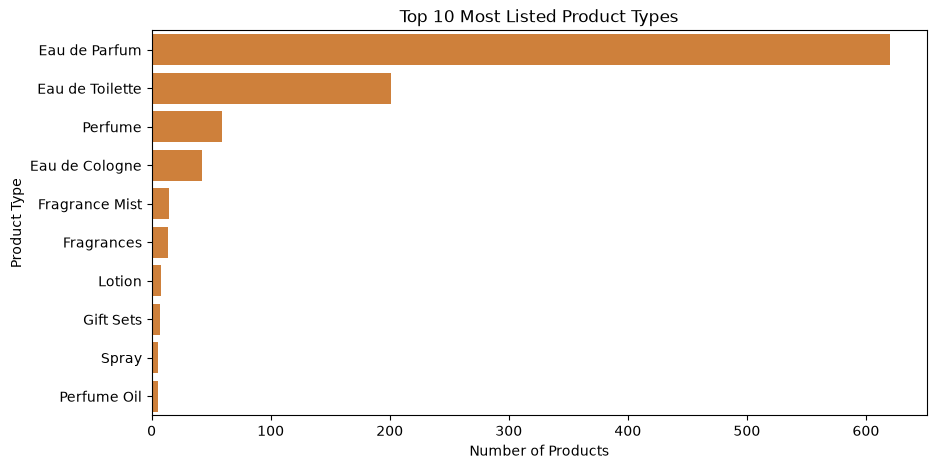

In [119]:
top10_types = df["type"].value_counts().head(10) # Mengambil 10 tipe produk yang paling banyak muncul

plt.figure(figsize=(10, 5)) # menentukan ukuran grafik

sns.barplot( # membuat bar chart menggunakan seaborn
    x=top10_types.values, # menentukan kolom x sebagai jumlah produk dari setiap tipe
    y=top10_types.index, # menentukan kolom y sebagai nama dari tipe produk
    color="#E67E22" # menentukan warna bar
)

plt.title("Top 10 Most Listed Product Types") # memberikan judul grafik
plt.xlabel("Number of Products") # memberikan label/keterangan jumlah produk
plt.ylabel("Product Type") # memberikan lable/ketenrangan nama produk
plt.show() # memunculkan grafik

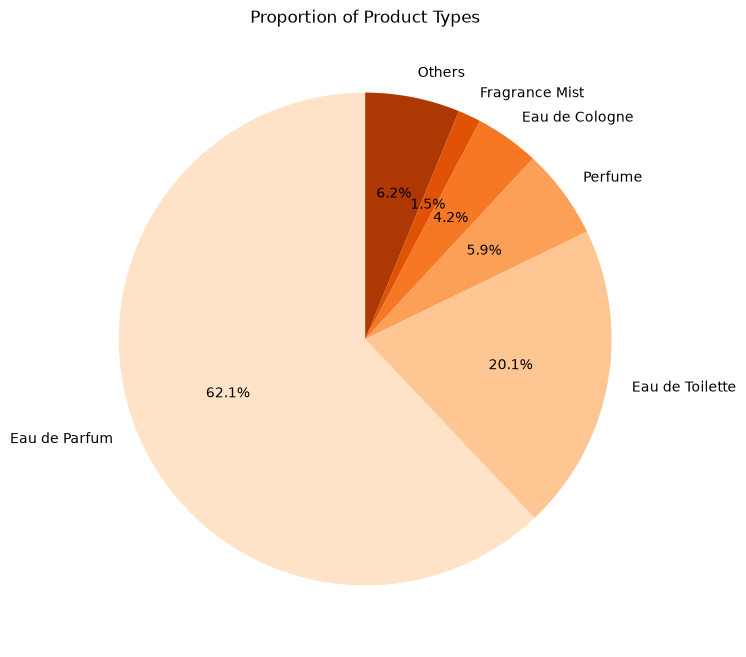

In [120]:
type_counts = df["type"].value_counts() # Menghitung jumlah kemunculan masing-masing tipe produk

top_5_types = type_counts.head(5) # mengambil 5 tipe produk yang paling sering muncul
others = type_counts.iloc[5:].sum() # menjumlahkan semua tipe produk selain 5 terbanyak menjadi others

type_pie = pd.concat([ # menggabungkan top 5 dengan kategori others
    top_5_types, # data top 5
    pd.Series({"Others": others}) # data others
])

plt.figure(figsize=(8, 8)) # menentukan ukuran pie chart

orange_colors = sns.color_palette( # Menentukan gradasi warna sesuai jumlah kategori
    "Oranges",
    n_colors=len(type_pie)
)

plt.pie( # membuat pie chart dengan matplotlib
    type_pie.values,  # jumlah produk
    labels=type_pie.index, # nama tipe produk
    autopct="%1.1f%%", # menampilkan presentase 1 angka desimal
    startangle=90, # memilai pie chart dari sudut 90 drajat (supaya lebih rapih)
    colors=orange_colors # menggunakan gradasi warna orange
)

plt.title("Proportion of Product Types") #memberikan judul pie chart
plt.show() # memunculkan pie chart

Penjelasan : 

Berdasarkan bar chart yang sudah dibuat, dapat dilihat bahwa listing dari product type terbesar adalah eau de parfum, lalu diikuti oleh eau de Toillet. Sedangkan sisa kategori product type hanya merepresentasikan sebagian kecil dari total listing yang ada.

Secara proporsi, dapat dilihat lebih jelas juga pada pie chart yang menunjukan bahwa Eau De Parfum dan Eau De toillet mendominasi total keseluruhan dataset, sedangkan sisa data hanya merepresentasikan sekitar 18% dari total keseluruhan data.

### Top 10 Most Listed Brands

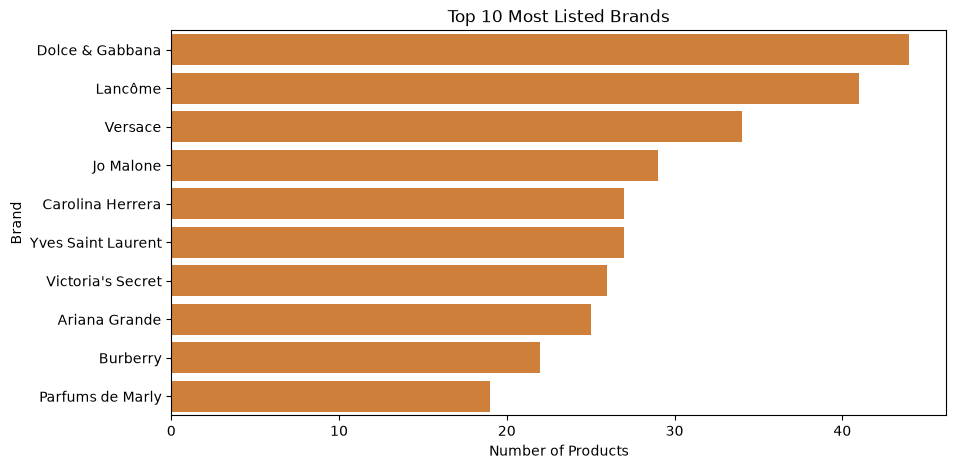

In [121]:
top_brands = df["brand"].value_counts().head(10) #mengambil 10 brand dengan jumlah produk yang paling banyak muncul

plt.figure(figsize=(10, 5)) # mengatur ukuran grafik

sns.barplot( # membuat bar chart menggunakan seaborn
    x=top_brands.values, # jumlah porduk dari setiap brand pada x
    y=top_brands.index, # nama brand pada y
    color="#E67E22" # menentukan warna bar
)

plt.title("Top 10 Most Listed Brands") # menambahkan judul
plt.xlabel("Number of Products") # menambahkan lable jumlah produk di x
plt.ylabel("Brand") # menambahkan label brand pada y
plt.show() # memunculkan grafik

Penjelasan : 

Berdasarkan bar chart yang sudah dibuat, dapat dilihat bahwa listing dari brand terbanyak adalah Dolce & Gabana, lalu diikuti oleh Lancome. Namun perbedaan total listing dengan brand lain tidak terlalu extreem. Hal ini menggambarkan bahwa produk pada dataset cukup tersebar kedalam berbagai brand.

## Bivariate Analysis

### Price vs Sold

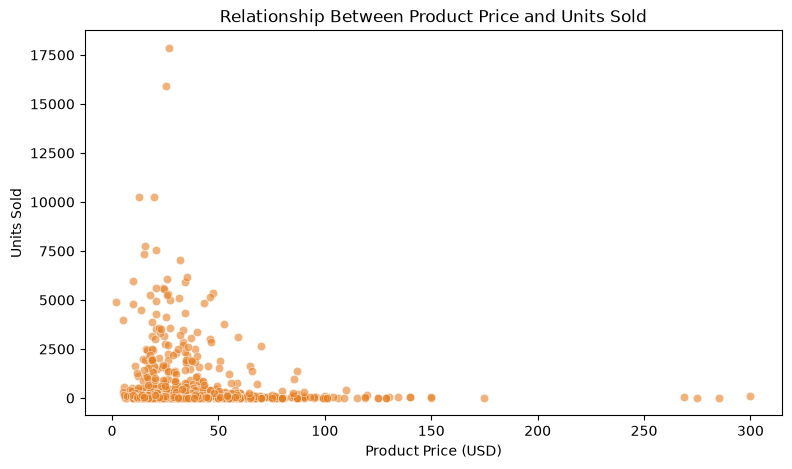

Correlation between Price and Sold: -0.142


In [122]:
plt.figure(figsize=(9, 5)) # Menentukan ukuran grafik

sns.scatterplot( # Fungsi Seaborn untuk membuat Scatter Plot
    data=df, # Menggunakan data dari df
    x="price", # Harga Produk pada x
    y="sold", # Jumlah Produk terjual pada y
    color="#E67E22", # Menentukan warna
    alpha=0.6 # mengatur transparansi warna pada titik di scatter plot
)

plt.title("Relationship Between Product Price and Units Sold") # Memberikan Judul
plt.xlabel("Product Price (USD)") # Memberikan Label Product Price pada X
plt.ylabel("Units Sold") # Memberikan Lable Units Sold pada y
plt.show() # Memunculkan grafik

price_sold_corr = df["price"].corr(df["sold"]) #menghitung korelasi antara harga dan jumlah produk terjual

print("Correlation between Price and Sold:",round(price_sold_corr, 3)) # menampilkan hasil korelasi, dengan pembulatan 3 angka desimal

Penjelasan :

Berdasarkan Scatterplot yang telah dibuat, dapat dilihat bahwa produk dengan jumlah penjualan tinggi umumnya berada pada kisaran harga rendah hingga menengah. Sementara itu, produk dengan harga tinggi cenderung memiliki jumlah penjualan yang lebih rendah.

Nilai korelasi antara harga dan jumlah produk terjual adalah -0.142. Berdasarkan nilai tersebut, hubungan korelasi antara price dan unit sold tergolong berhubungan negative namun lemah, yang berarti kenaikan harga cenderung mengurangi jumlah penjualan namun tidak signifikan.

Selain itu dapat dilihat juga ada beberapa produk pada rentang harga 20-40 dollar memiliki penjualan yang sangat tinggi, sekitar 17.500 unit, yang dapat diindikasi sebagai produk Best-Selling.

### Top 10 Best-Selling Brands

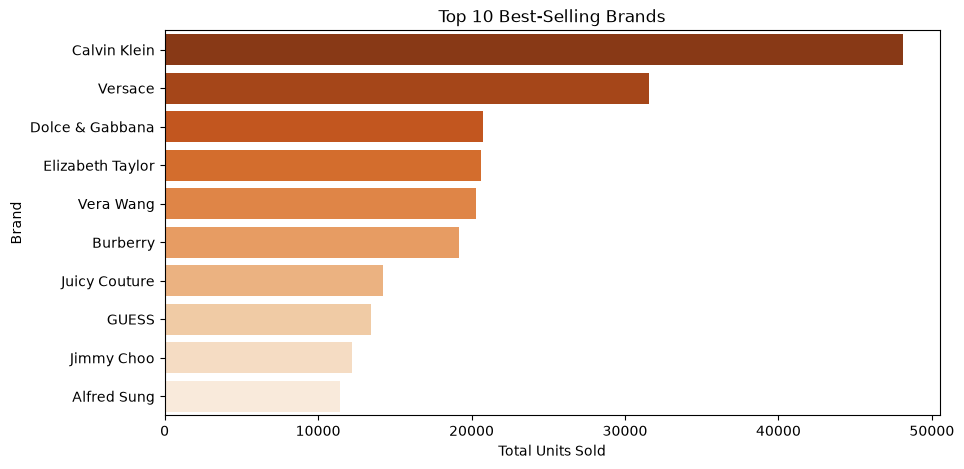

In [123]:
plt.figure(figsize=(10, 5)) # menentukan ukuran grafik

orange_palette = sns.color_palette( # membuat gradasi warnna sesuai nama brand
    "Oranges_r", # Menggunakan palette warna orange tapi dibalik supaya lebih tua ke muda
    n_colors=len(top_brand_sold) # jumlah warna sesuai dengan jumlah brand
)

sns.barplot( # membuat bar chart menggunakan fungsi seaborn
    x=top_brand_sold.values, # Total unit terjual di x
    y=top_brand_sold.index, # nama brand di y
    hue=top_brand_sold.index, # memberikan warna berbeda untuk setiap brand
    palette=orange_palette, # menggunakan gradasi warna orange
    legend=False # menghilangkan legend
)

plt.title("Top 10 Best-Selling Brands") # memberikan judul
plt.xlabel("Total Units Sold") # memberikan label di x
plt.ylabel("Brand") # memberikan label di y
plt.show() # memunculkan grafik

In [124]:
top_brand_sold = ( # mengelompokan data berdasarkan brand
    df.groupby("brand")["sold"] # Mengelompokan brand dan mengambil kolom sold
    .sum() # menjumlahkan total penjualan setiap brand
    .sort_values(ascending=False) # mengurutkan dari penjualan terbesar ke terkecil
    .head(10) # mengambil 19 brand dengan penjualan tertinggi
)

display(top_brand_sold) # memunculkan total penjualan top 10 brand

brand
Calvin Klein        48100
Versace             31561
Dolce & Gabbana     20745
Elizabeth Taylor    20649
Vera Wang           20308
Burberry            19179
Juicy Couture       14258
GUESS               13480
Jimmy Choo          12204
Alfred Sung         11451
Name: sold, dtype: int64

Penjelasan :

Berdasarkan Bar Chart diatas, Calvin Klein merupakan brand dengan total penjualan tertinggi, yaitu 48,100 unit, diikuti Versace dengan 31,561 unit. Total penjualan Calvin Klein sekitar 52% lebih tinggi dibandingkan Versace, sehingga menunjukkan performa penjualan yang cukup dominan.

Dolce & Gabbana berada di posisi ketiga dengan 20,745 unit. Dolce & Gabbana sebelumnya memiliki jumlah listing terbanyak, tetapi bukan brand dengan total penjualan tertinggi. Hal tersebut menunjukkan bahwa banyaknya produk yang tersedia atau di listing tidak selalu menghasilkan total penjualan yang lebih tinggi. 

Dalam bisnis parfum ada beberapa faktor lain yang dapat menentukan tinggi atau rendahnya penjualan suatu brand, mulai dari Popularitas brand, harga, value brand, dan berbagai faktor lain yang dapat membuat customer lebih tertarik dengan brand tersebut.

### Top 10 Best-Selling Product Types

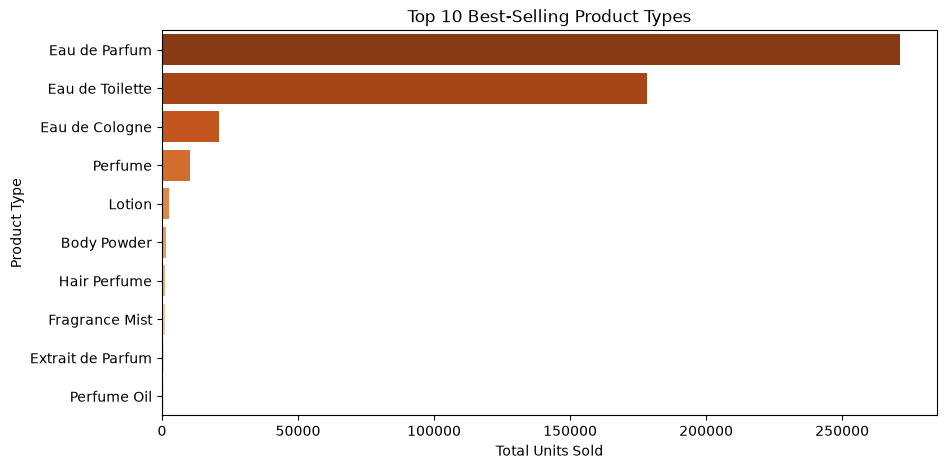

In [125]:
plt.figure(figsize=(10, 5)) # Menentukan ukuran grafik

orange_palette = sns.color_palette( # membuat gradasi warna
    "Oranges_r", # menggunakan pallete
    n_colors=len(top_type_sold)) # jumlah warna sesuai dengan jumlah tipe produk


sns.barplot( # menggunakan fungsi seaborn untuk membuat bar chart
    x=top_type_sold.values, # total unit di x
    y=top_type_sold.index, # nama tipe produk di y
    hue=top_type_sold.index, # memberikan warna berbeda pada setiap tipe
    palette=orange_palette, # menggunakan gradasi warna orange
    legend=False) # menghilangakan legend

plt.title("Top 10 Best-Selling Product Types") # membuat judul
plt.xlabel("Total Units Sold") # membuat label x
plt.ylabel("Product Type") # membuat label y
plt.show() # memunculkan grafik

In [126]:
top_type_sold = (
    df.groupby("type")["sold"] # mengelompokan berdasarkan type dan mengambil isi kolom sold
    .sum() # menjumlahkan total penjualan berdasarkan tipe
    .sort_values(ascending=False) # mengurutkan dari besar ke kecil
    .head(10)) # mengambil 10 tipe produk dengan penjualan tertinggi

display(top_type_sold) # memunculkan data

type
Eau de Parfum        271299
Eau de Toilette      178215
Eau de Cologne        20874
Perfume               10208
Lotion                 2507
Body Powder            1454
Hair Perfume           1130
Fragrance Mist          995
Extrait de Parfum       689
Perfume Oil             618
Name: sold, dtype: int64

Penjelasan :

Berdasarkan barchart diatas, Eau de Parfum merupakan tipe produk dengan total penjualan tertinggi, dengan penjualan sebesar 271,299 unit, diikuti Eau de Toilette dengan penjualan sebesar 178,215 unit.

Diluar kedua kategori tersebut, terjadi perbedaan penjualan yang sangat besar. Eau de Cologne yang berada di posisi ketiga hanya terjual 20,874 unit penjualan, sedangkan Perfume hanya terjual 10,208 unit, yang secara proporsi jumlah penjualannya hanya 1/10 dibanding Eau de Parfume.

Hasil tersebut sesuai dengan analisis univariate sebelumnya yang menunjukkan bahwa Eau de Parfum dan Eau de Toilette memiliki jumlah listing terbanyak. Artinya, kedua kategori tersebut tidak hanya paling banyak ditampilkan atau di listing, tetapi juga memberikan kontribusi penjualan yang cukup besar.

## Multivariate Analysis

### Relationship Between Price, Sales, and Product Type

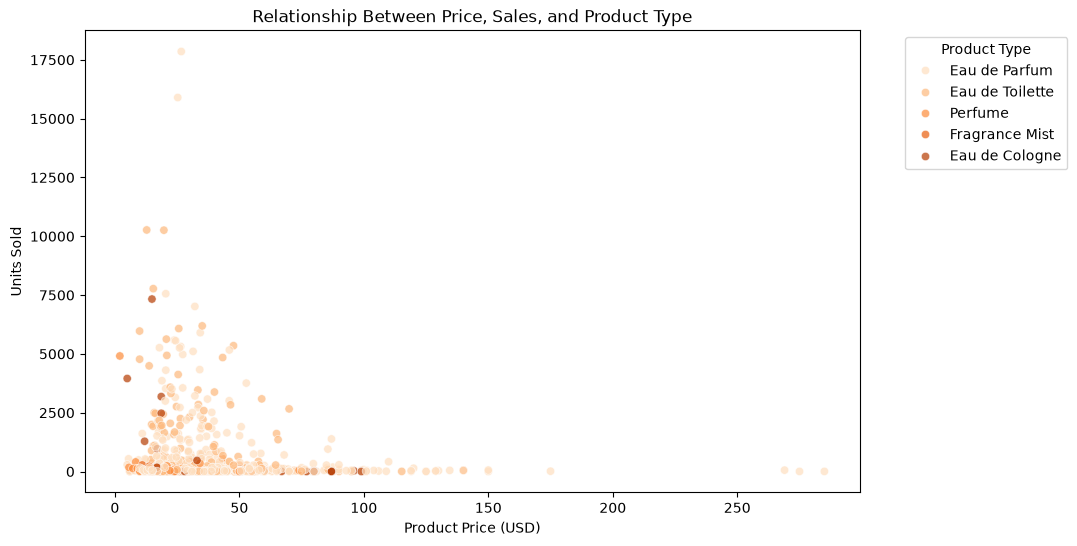

In [127]:
top_5_type_names = df["type"].value_counts().head(5).index # Memuncukal nama 5 tipe produk yang paling banyak muncul

df_top_types = df[ # membuat filter dataset yang berisi 5 tipe produk teratas
    df["type"].isin(top_5_type_names) # cek apakah type termasuk top 5
]

plt.figure(figsize=(10, 6)) # menentukan ukuran grafik

sns.scatterplot( # membuat scatter plot dengan fungsi seaborn
    data=df_top_types, # menggunakan data top 5 produk yang sudah di filter
    x="price", # harga produk di x
    y="sold", # penjualan produk di y
    hue="type", # membedakan warna berdasarkan tipe produk
    palette="Oranges", # menggunakan palette warna orange
    alpha=0.7 # Mengatur transparansi titik pada scatter plot
)

plt.title("Relationship Between Price, Sales, and Product Type") # memberikan judul
plt.xlabel("Product Price (USD)") # memberikan label x
plt.ylabel("Units Sold") # memberikan label y
plt.legend( # menentukan legend
    title="Product Type", # judul legend
    bbox_to_anchor=(1.05, 1), # menempatkan legend diluar grafik
    loc="upper left" # menempatkan legend di kiri atas
)
plt.show() # memunculkan scatter plot

Penjelasan :

Berdasarkan scatter plot diatas, secara visual dapat dilihat bahwa produk dengan penjualan tinggi umumnya berada pada kisaran harga rendah hingga menengah, terutama sekitar 10–60 USD. Pada harga yang semakin tinggi, jumlah produk terjual cenderung lebih rendah.

Eau de Parfum terlihat paling dominan dalam persebaran data dan mencakup beberapa produk dengan penjualan tertinggi. Hal ini sejalan dengan hasil analisis sebelumnya yang menunjukkan bahwa Eau de Parfum memiliki jumlah listing dan total penjualan terbesar.

Meskipun terdapat perbedaan tipe produk, mayoritas titik dari setiap kategori masih terkonsentrasi pada jumlah penjualan yang relatif rendah. Hal tersebut menunjukkan bahwa tipe produk saja belum cukup untuk menjelaskan perbedaan performa penjualan.

Beberapa produk dengan harga rendah hingga menengah memiliki penjualan yang sangat tinggi dan dapat dikategorikan sebagai potential best-selling outliers.

## Advanced Visualization

### Correlation Heatmap

In [128]:
numeric_columns = ["price", "available", "sold"] # menentukan kolom

correlation_matrix = df[numeric_columns].corr() # menghitung korelasi
 
display(correlation_matrix) # menampilkan hasil korelasi

,price,available,sold
price,1.000000,-0.138699,-0.142246
available,-0.138699,1.000000,0.227868
sold,-0.142246,0.227868,1.000000


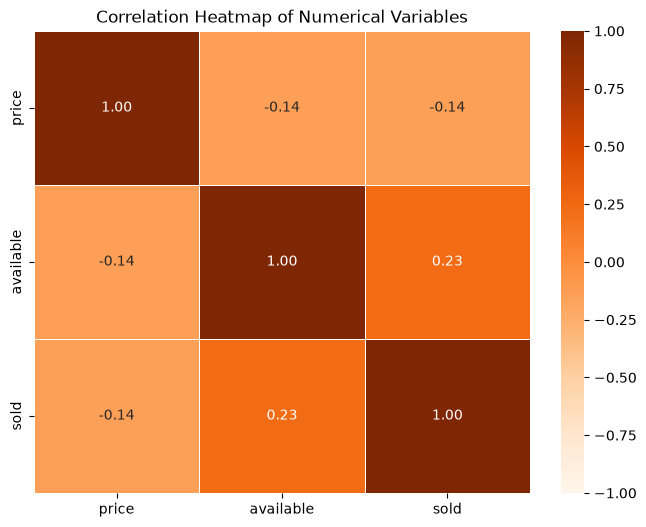

In [129]:
plt.figure(figsize=(8, 6)) # menentukan ukuran grafik

sns.heatmap( # membuat heatmap dari fungsi seaborn
    correlation_matrix, # Data yang digunakan berdasar dari correlation matrix pada query diatas
    annot=True, # menampilkan nilai korelasi didalam kotak
    cmap="Oranges", # Menggunakan gradasi warna orange
    fmt=".2f", # membulatkan angka menjadi 2 angka desimal
    linewidths=0.5, # memberikan garis pemisah antar kotak
    vmin=-1, # menentukan nilai minimum korelasi
    vmax=1) # menentukan nilai maksimum korelasi

plt.title("Correlation Heatmap of Numerical Variables") # judul heatmap
plt.show() # memunculkan heat map

Penjelasan :

Correlation heatmap menunjukkan bahwa tidak terdapat hubungan linear yang kuat antara price, available, dan sold.

Price memiliki korelasi negatif sangat lemah dengan sold sebesar -0.14, yang menunjukan produk dengan harga lebih tinggi cenderung lebih sulit terjual, tetapi tidak signifikan.

Price juga memiliki korelasi negatif sangat lemah dengan available sebesar -0.14. Hal ini menunjukkan bahwa produk yang lebih mahal sedikit cenderung memiliki jumlah stok yang lebih rendah.

Sementara itu, available memiliki korelasi positif lemah dengan sold sebesar 0.23. Produk yang memiliki stok lebih banyak cenderung memiliki jumlah penjualan yang sedikit lebih tinggi.

### Pairplot of Numerical Variables by Product Type

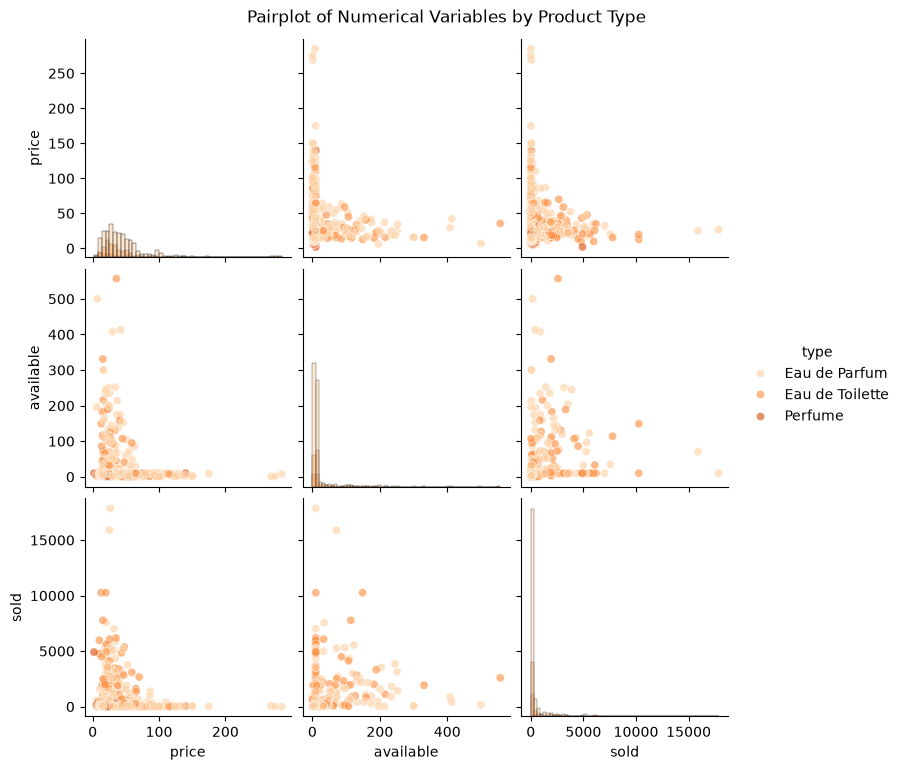

In [130]:
top_3_type_names = df["type"].value_counts().head(3).index # mengambil nama 3 tipe produk terbanyak

pairplot_data = df[ df["type"].isin(top_3_type_names)][["price", "available", "sold", "type"]] #mengisi data dengan filter top 3 type

sns.pairplot( # membuat pairplot dengan fungsi seaborn
    data=pairplot_data, # menggunakan data filter top 3 type
    vars=["price", "available", "sold"], # menentukan variable yang dibandingkan
    hue="type", # membedakan warna berdasarkan type produk
    palette="Oranges", # menggunakan pallete warna orange
    diag_kind="hist", # menamoilkan histogram pada bagian diagonal
    plot_kws={
        "alpha": 0.6, # mengatur transparansi titik
        "s": 35}) # mengatur ukuran titik

plt.suptitle("Pairplot of Numerical Variables by Product Type",y=1.02) # memberikan judul dan posisinya

plt.show() # memunculkan pairplot

Penjelasan :

Pairplot menunjukkan bahwa distribusi price, available, dan sold pada tiga tipe produk utama cenderung right-skewed. Mayoritas produk memiliki harga, persediaan, dan penjualan yang relatif rendah, sementara hanya beberapa produk memiliki nilai yang sangat tinggi.

Hubungan antara price dan sold terlihat lemah. Produk dengan penjualan tertinggi lebih banyak ditemukan pada kisaran harga rendah hingga menengah, tetapi sebagian besar produk pada rentang harga tersebut tetap memiliki penjualan rendah.

Available dan sold menunjukkan kecenderungan hubungan positif. Beberapa produk dengan persediaan lebih tinggi juga memiliki jumlah penjualan yang lebih tinggi, meskipun pola tersebut tidak konsisten pada seluruh data.

Eau de Parfum mendominasi jumlah titik karena merupakan kategori dengan jumlah produk terbanyak. Namun, ketiga tipe produk memiliki pola distribusi yang relatif sama.

## Advanced Exploratory Data Analysis

### Filtering High-Selling Products

In [131]:
sold_q3 = df["sold"].quantile(0.75) #menghitung nilai quartile q3

high_selling_products = ( # Filter produk dengan penjualan diatas q3 
    df[df["sold"] > sold_q3]
    .sort_values(by="sold", ascending=False))

display( # menampilkan 10 produk dengan penjualan tertinggi
    high_selling_products[
        ["title", "brand", "type", "price", "available", "sold"]
    ].head(10))

print("Third Quartile (Q3) of Sold :", sold_q3) # menampilkan nilai q3
print("Number of High-Selling Products :", len(high_selling_products)) # menampilkan jumlah yang termasuk high selling product

,title,brand,type,price,available,sold
345,Escape by Calvin Klein EDP Perfume for Women 3...,Calvin Klein,Eau de Parfum,26.66,10,17854
359,VERA WANG Perfume 3.3 / 3.4 oz EDP For Women S...,Vera Wang,Eau de Parfum,25.25,71,15897
108,VANDERBILT by Gloria 3.4 oz 3.3 edt for Women ...,Gloria Vanderbilt,Eau de Toilette,12.78,149,10268
172,White Diamonds by Elizabeth Taylor 3.3 3.4 oz ...,Elizabeth Taylor,Eau de Toilette,19.68,10,10259
386,RED by GIORGIO BEVERLY HILLS women edt spray P...,Giorgio Beverly Hills,Eau de Toilette,15.42,114,7773
203,Guess Marciano perfume for women EDP 3.3 / 3.4...,GUESS,Eau de Parfum,20.44,35,7558
205,Exclamation by Coty Perfume for Women Cologne ...,Coty,Eau de Cologne,14.89,10,7331
180,Eternity by CK Calvin Klein 3.4 oz EDP Perfume...,Calvin Klein,Eau de Parfum,32.12,10,7018
195,Brit Sheer by Burberry 3.3 / 3.4 oz EDT Perfum...,Burberry,Eau de Toilette,35.08,10,6191
392,360 by Perry Ellis Perfume 3.3 / 3.4 oz Spray ...,Perry Ellis,Eau de Toilette,25.66,33,6077


Third Quartile (Q3) of Sold : 257.0
Number of High-Selling Products : 250


Penjelasan :

Nilai Q3 dari sold adalah 257 unit. Maka, produk dengan penjualan lebih dari 257 unit dikategorikan sebagai high-selling products. Setelah dilakukan filtering, ditemukan 250 produk.

Produk dengan penjualan tertinggi adalah Escape by Calvin Klein dengan 17,854 unit, diikuti produk Vera Wang dengan 15,897 unit. Produk lain dari Gloria Vanderbilt dan Elizabeth Taylor juga mencapai lebih dari 10,000 unit penjualan.

Mayoritas produk terlaris dalam tabel berasal dari kategori Eau de Parfum dan Eau de Toilette. Selain itu, harga sepuluh produk terlaris berada pada kisaran relatif terjangkau, yaitu sekitar 12.78–35.08 usd.

Hal tersebut mendukung hasil analisis sebelumnya bahwa produk dengan penjualan sangat tinggi cenderung memiliki rentang harga rendah hingga menengah. Namun, faktor brand dan tipe produk juga diindikasi berkontribusi terhadap tingginya penjualan.

### Grouping and Aggregation by Product Type

In [132]:
type_performance = (df.groupby("type") # mengelompokan data berdasarkan tipe produk dan menghitung performa
    .agg(number_of_products=("title", "count"), # menghitung jumlah produk
        total_sold=("sold", "sum"), # menghitung total produk terjual
        average_sold=("sold", "mean"), # menghitung rata-rata penjualan
        median_price=("price", "median"), # menghitung median harga
        average_available=("available", "mean")) # menghitung rata-rata ketersediaan barang
    .sort_values(by="total_sold", ascending=False)) # mengurutkan berdasarkan total penjualan tertinggi

display(type_performance.head(10))

,number_of_products,total_sold,average_sold,median_price,average_available
type,,,,,
Eau de Parfum,620,271299,437.579032,36.865,19.845161
Eau de Toilette,201,178215,886.641791,29.990,25.641791
Eau de Cologne,42,20874,497.000000,49.990,8.904762
Perfume,59,10208,173.016949,23.990,7.542373
Lotion,8,2507,313.375000,25.700,6.250000
Body Powder,1,1454,1454.000000,14.940,3.000000
Hair Perfume,1,1130,1130.000000,12.360,417.000000
Fragrance Mist,15,995,66.333333,19.000,7.000000
Extrait de Parfum,3,689,229.666667,58.500,10.000000


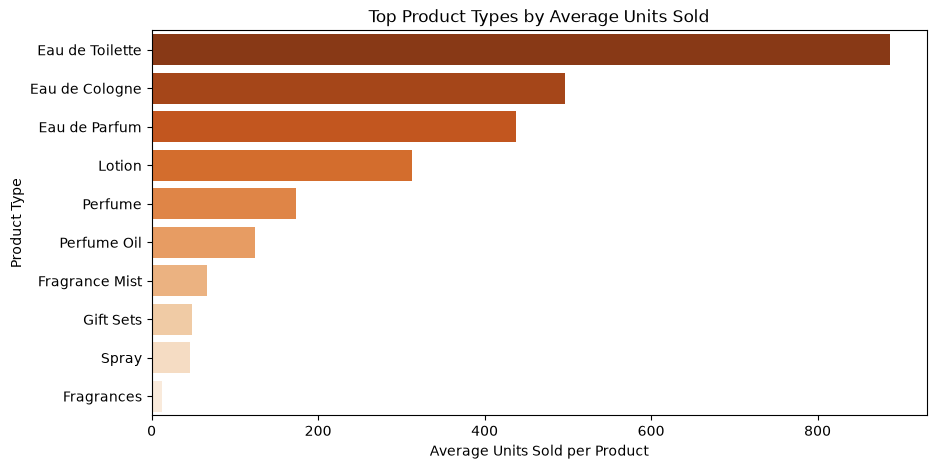

In [133]:
reliable_types = (type_performance[type_performance["number_of_products"] >= 5] # filter tipe produk dengan minimal 5 produk
    .sort_values(by="average_sold", ascending=False) # mengurutkan berdasarkan rata-rata penjualan tertinggi
    .head(10)) # memunculkan 10 produk tertinggi

plt.figure(figsize=(10, 5)) # menentukan ukuran grafik

orange_palette = sns.color_palette( #membuat gradasi warna orange
    "Oranges_r",
    n_colors=len(reliable_types))

sns.barplot( # membuat bar chart menggunakan seaborn
    data=reliable_types, # menentukan data
    x="average_sold", # rata-rata unit terjual di x
    y=reliable_types.index, # tipe produk di y
    hue=reliable_types.index, # membedakan warna berdasarkan tipe produk
    palette=orange_palette, # menggunakan gradasi warna orange
    legend=False) # menyembunyikan legend

plt.title("Top Product Types by Average Units Sold") # menentukan judul
plt.xlabel("Average Units Sold per Product") # menentukan label x
plt.ylabel("Product Type") # menentukan label y
plt.show() # memunculkan grafik

Penjelasan :

Eau de Parfum memiliki total penjualan tertinggi sebesar 271,299 unit. Namun, kategori ini juga memiliki jumlah produk paling banyak, yaitu 620 produk, sehingga rata-rata penjualannya sebesar 437.58 unit per produk.

Eau de Toilette memiliki rata-rata penjualan tertinggi sebesar 886.64 unit per produk, hampir dua kali rata-rata Eau de Parfum. Hal ini menunjukkan bahwa secara rata-rata, setiap produk Eau de Toilette memiliki performa penjualan yang lebih tinggi.

Hasil ini menunjukkan bahwa dominasi total penjualan Eau de Parfum terutama dipengaruhi oleh jumlah produknya yang sangat banyak. Sementara itu, Eau de Toilette menunjukkan performa penjualan per produk yang lebih baik.

### Crosstab of Product Type and Sales Category

In [134]:
df["sales_category"] = pd.qcut( # Membagi data penjualan menjadi 3 kategori sesuai quantile
    df["sold"],
    q=3, # membagi data menjadi 3 kelompok
    labels=["Low", "Medium", "High"]) # memberikan nama pada setiap kelompok

top_5_type_names = df["type"].value_counts().head(5).index # mengambil 5 tipe produk yang paling banyak muncul

crosstab_sales = pd.crosstab( # membuat tabel perbandingan tipe produk dengan kategori penjualan
    df.loc[df["type"].isin(top_5_type_names), "type"], # menentukan baris berdasarkan tipe produk
    df.loc[df["type"].isin(top_5_type_names), "sales_category"]) # menentukan kolom berdasarkan kategori penjualan

crosstab_sales = crosstab_sales[["Low", "Medium", "High"]] # mengurutkan kolom kategori penjualan

display(crosstab_sales) # menampilkan hasil crosstab

sales_category,Low,Medium,High
type,,,
Eau de Cologne,22,11,9
Eau de Parfum,204,217,199
Eau de Toilette,47,56,98
Fragrance Mist,7,6,2
Perfume,22,24,13


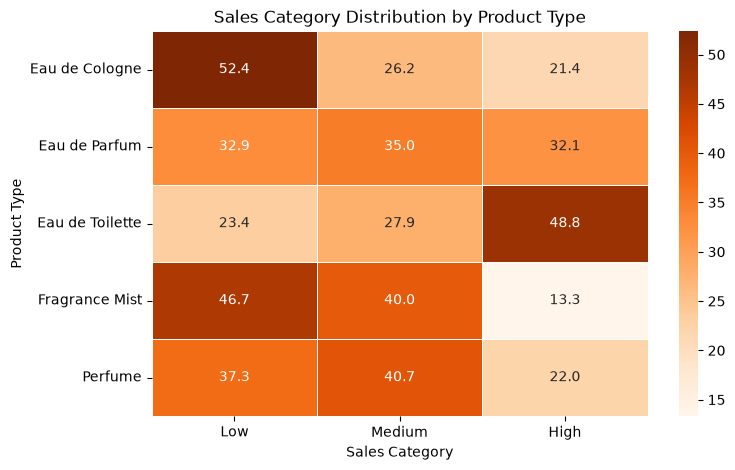

In [135]:
crosstab_percentage = pd.crosstab( # membuat crosstab dalam bentuk presentase untuk setiap tipe
    df.loc[df["type"].isin(top_5_type_names), "type"], # menentukan baris berdasarkan tipe produk
    df.loc[df["type"].isin(top_5_type_names), "sales_category"], # menentukan kolom berdasarkan kategori penjualan
    normalize="index" # mengubah nilai menjadi proporsi per tipe produk
) * 100 # mengubah menjadi presentase

crosstab_percentage = crosstab_percentage[ # mengurutkan kolom kategori penjualan
    ["Low", "Medium", "High"]
]

plt.figure(figsize=(8, 5)) # mengatur ukuran grafik

sns.heatmap( # membuat heatmap dengan seaborn
    crosstab_percentage, # menggunakan data crosstab yang sudah dibuat
    annot=True, # menampilkan nilai dalam kotak
    fmt=".1f", # membulatkan menjadi 1 angka desimal
    cmap="Oranges", # menggunakan gradasi warna orange
    linewidths=0.5 # membuat garis pemisah antar kotak
)

plt.title("Sales Category Distribution by Product Type") # memberikan judul
plt.xlabel("Sales Category") # memberikan label pada x
plt.ylabel("Product Type") # memberikan label pada y
plt.show() #menampilkan grafik

Penjelasan :

Eau de Toilette memiliki proporsi high-selling products terbesar, yaitu 48.8%. Hal ini memvalidasi hasil aggregation sebelumnya, dimana Eau de Toilette memiliki rata-rata penjualan per produk tertinggi.

Eau de Parfum memiliki distribusi yang relatif seimbang, yaitu 32.9% kategori Low, 35.0% Medium, dan 32.1% High. Meskipun memiliki total penjualan terbesar, tidak semua produk Eau de Parfum memiliki performa penjualan yang tinggi.

Dapat disimpulkan bahwa Eau de Toilette memiliki performa penjualan yang lebih konsisten di antara tipe produk utama. Sedangkan, penjualan Eau de Parfum lebih banyak didukung oleh jumlah listing yang besar.

### Random Sampling

In [136]:
df_sample = df.sample( # membuat sample
    frac=0.20, # mengambil 20% dari total data
    random_state=42) # membuat hasil random tetap sama

print("Population Size :", len(df)) # menampilkan jumlah populasi
print("Sample Size     :", len(df_sample)) # menampilkan sample size

display(df_sample.head(10)) # memunculkan 10 data pertama dalam sample

Population Size : 999
Sample Size     : 200


,brand,title,type,price,priceWithCurrency,available,availableText,sold,lastUpdated,itemLocation,InputNotes,sales_category
453,Dana,CHANTILLY for WOMEN by DANA * Big Size 3.5 oz ...,Eau de Toilette,24.95,US $24.95,7,7 available / 171 sold,171,2024-05-24 00:01:34,"Englewood, New Jersey, United States",,High
794,Al Haramain,L'aventure Ciel by Al Haramain Eau De Parfum 3...,Eau de Parfum,33.75,US $33.75,10,More than 10 available / 10 sold,10,2024-05-23 16:06:10,"Long Island City, New York, United States",,Low
209,Dolce & Gabbana,Light Blue eau Intense by Dolce & Gabbana D&G ...,Eau de Parfum,52.78,US $52.78,10,"Limited quantity available / 3,759 sold",3759,2024-05-24 07:50:02,"Hackensack, New Jersey, United States",available diisi median,High
309,Viktor & Rolf,VIKTOR & ROLF FLOWERBOMB EAU DE PARFUM TRAVEL ...,Eau de Parfum,9.99,US $9.99,10,More than 10 available / 10 sold,10,NaT,"Hicksville, New York, United States",,Low
741,Givenchy,Givenchy Irresistible For Women Eau de Parfum...,Eau de Parfum,21.90,US $21.90/ea,7,7 available / 4 sold,4,2024-04-23 13:27:49,"Rowlett, Texas, United States",,Low
578,Yves Saint Laurent,Yves Saint Laurent Black Opium Women's Perfume...,Eau de Parfum,45.99,US $45.99,1,Last One / 27 sold,27,2024-05-24 00:07:54,"Stuyvesant Falls, New York, United States",,Medium
896,Burberry,BURBERRY LONDON WOMEN *CLASSIC* 0.15 oz / 4.5 ...,Eau de Parfum,11.49,US $11.49,10,More than 10 available / 20 sold,20,2024-05-13 11:28:03,"Spring Valley, New York, United States",,Low
545,Vera Wang,Flower Princess by Vera Wang for women EDT 3.3...,Eau de Toilette,19.54,US $19.54/ea,19,19 available / 288 sold,288,2024-05-11 09:46:06,"Dallas, Texas, United States",,High
436,Jimmy Choo,JIMMY CHOO ILLICIT FLOWER by Jimmy Choo perfum...,Eau de Toilette,34.43,US $34.43/ea,16,16 available / 563 sold,563,2024-05-24 07:50:09,"Dallas, Texas, United States",,High
679,diptyque,2x Authentic Diptyque Orpheon Eau de Parfum Sp...,Eau de Parfum,27.50,US $27.50,9,9 available / 12 sold,12,2024-05-23 10:38:20,"Tulsa, Oklahoma, United States",,Low


In [137]:
sample_comparison = pd.DataFrame({ # membuat dataframe untuk membandingkan rata-rata populasi dan sampel
    "Population Mean": [ 
        df["price"].mean(), # rata-rata harga seluruh data
        df["available"].mean(), # rata-rata ketersediaan barang seluruh data
        df["sold"].mean() # rata-rata penjualan seluruh data
    ],
    "Sample Mean": [
        df_sample["price"].mean(), # rata-rata harga data sampel
        df_sample["available"].mean(), # rata-rata ketersediaan barang data sampel
        df_sample["sold"].mean() # rata-rata penjualan barang data sampel
    ]}, index=["price", "available", "sold"])

sample_comparison["Difference"] = ( # menghitung rata-rata sampel dengan rata-rata populasi
    sample_comparison["Sample Mean"]
    - sample_comparison["Population Mean"])

sample_comparison = sample_comparison.round(2) # membulatkan hasil menjadi 2 angka desimal

display(sample_comparison) # memunculkan hasil perbandingan

,Population Mean,Sample Mean,Difference
price,39.88,40.35,0.46
available,19.33,19.14,-0.19
sold,490.64,472.52,-18.11


Penjelasan :

Hasil random sampling terhadap 20% sample acak menunjukkan bahwa sampel mencakup produk dengan kategori penjualan yang beragam, mulai dari Low, Medium, hingga High. 

Jika dibandingkan dengan keseluruhan populasi, rata-rata harga sampel sebesar 40,35 usd sangat mendekati rata-rata populasi sebesar 39,88 usd, dengan selisih hanya 0,46. 

Rata-rata produk available juga hampir sama, yaitu 19,14 unit pada sampel dibandingkan 19,33 unit pada populasi.

Pada variabel penjualan (sold), rata-rata sampel sebesar 472,52 unit, sedikit lebih rendah dibandingkan rata-rata populasi sebesar 490,64 unit, dengan selisih 18,11 unit. 

Secara keseluruhan, kecilnya perbedaan rata-rata antara sampel dan populasi menunjukkan bahwa sampel yang diambil cukup mampu menggambarkan karakteristik umum dataset, terutama dari sisi harga dan ketersediaan produk.

## Insights

1. Distribusi price dan sold bersifat right-skewed. Mayoritas produk berada pada tingkat harga dan penjualan relatif rendah hingga menengah, sedangkan hanya beberapa produk memiliki harga atau penjualan yang sangat tinggi.

2. Hubungan antara price dan sold bersifat negatif sangat lemah dengan korelasi -0.14. Produk dengan harga lebih tinggi sedikit cenderung memiliki penjualan lebih rendah, namun harga tidak bisa menjelaskan performa penjualan secara keseluruhan.

3. Available dan sold memiliki korelasi positif lemah sebesar 0.23. Produk dengan penjualan lebih tinggi, cenderung memiliki persediaan lebih banyak, namun tidak signifikan.

4. Calvin Klein menjadi brand dengan total penjualan tertinggi dengan total terjual 48,100 unit, walaupun Dolce & Gabbana memiliki jumlah listing terbanyak. Hal ini menunjukan, banyaknya listing tidak selalu menghasilkan total penjualan tertinggi.

5. Eau de Parfum memiliki total penjualan tertinggi sebesar 271,299 unit karena memiliki jumlah produk paling banyak. Namun, Eau de Toilette memiliki rata-rata penjualan tertinggi sebesar 886.64 unit per produk.

6. Sebanyak 48.8% produk Eau de Toilette termasuk kategori high-selling. Proporsi ini merupakan yang tertinggi di antara tipe produk utama.

7. Produk dengan penjualan tertinggi umumnya berada pada kisaran harga rendah hingga menengah. Sepuluh produk terlaris memiliki harga sekitar USD 12.78–35.08.

8. Sampel acak sebesar 20% memiliki nilai rata-rata yang cukup mendekati populasi sehingga dapat merepresentasikan karakteristik utama dataset.

## Conclusion

Analisis menunjukkan bahwa performa penjualan produk parfum tidak dapat dijelaskan hanya berdasarkan harga. Hubungan antara harga dan jumlah penjualan sangat lemah, sehingga faktor lain seperti brand, tipe produk, popularitas, dan ketersediaan kemungkinan turut berperan.

Eau de Parfum memberikan kontribusi total penjualan terbesar karena mendominasi jumlah listing. Namun, Eau de Toilette menunjukkan performa yang lebih efisien berdasarkan rata-rata penjualan per produk dan proporsi high-selling products.

Calvin Klein merupakan brand dengan performa total penjualan terbaik, sedangkan produk-produk terlaris secara individual lebih banyak ditemukan pada rentang harga rendah hingga menengah.

## Recommendations

1. Memprioritaskan ketersediaan produk Eau de Toilette karena memiliki rata-rata penjualan per produk dan proporsi high-selling products tertinggi.

2. Tetap mempertahankan variasi Eau de Parfum karena kategori tersebut memberikan kontribusi terbesar terhadap total penjualan.

3. Memberikan saran kepada brand-brand yang sudah menjadi favorite untuk memperbanyak variasi tipe product Eau De Toillet sehingga dapat memaksimalkan potensi penjualan.

4. Memberikan saran kepada brand-brand lain yang belum perform rentang harga yang direkomenadasikan yaitu sekitar 12.78 - 35.08 serta menambahkan varian tipe produk Eau de Toillet untuk meningkatkan potensi penjualan walaupun tidak signifikan